These exploratory checks compare historical and retrained models, investigate loader initialization and temporal memory, and plot the results available before the temporal MLP experiments. Outputs are retained from the original Colab session.


In [ ]:
# ============================================================
# SETUP - Run this cell first
# ============================================================
!git clone -b feat/fair-comparison-experiments https://github.com/tatipar/temporalgnn-nids.git
import sys
sys.path.append('/content/temporalgnn-nids/code/python')

from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/nids-mitre/')

Cloning into 'temporalgnn-nids'...
remote: Enumerating objects: 2342, done.
remote: Counting objects: 100% (579/579), done.
remote: Compressing objects: 100% (403/403), done.
remote: Total 2342 (delta 348), reused 238 (delta 111), pack-reused 1763 (from 1)
Receiving objects: 100% (2342/2342), 14.14 MiB | 29.38 MiB/s, done.
Resolving deltas: 100% (1102/1102), done.
Mounted at /content/drive


In [ ]:
!pip install torch_geometric -q

In [ ]:
import hashlib
import importlib.util
import json
import platform
import random
from pathlib import Path

import numpy as np
import torch
import torch_geometric
import utils.models as original_module
from utils.datasets import NF_IDS_Dataset

ROOT = Path("/content/drive/MyDrive/nids-mitre")
FACTORIAL = ROOT / "results_stgnn_memory_message_factorial_v1"
SEED, BATCH_STEPS, UPDATES = 42, 10, 2


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


# Verificar qué implementaciones estamos comparando.
manifest = json.loads((FACTORIAL / "manifest.json").read_text())
model_path = FACTORIAL / "factorial_models.py"

assert sha256(model_path) == manifest["factorial_model_sha256"], (
    "El código factorial archivado cambió"
)

expected = manifest["pinned_source_hashes"]["code/python/utils/models.py"]
assert sha256(original_module.__file__) == expected, (
    "El utils.models importado difiere de la referencia del factorial: "
    + str(original_module.__file__)
)

spec = importlib.util.spec_from_file_location(
    "factorial_equivalence_diagnostic", model_path
)
factorial_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(factorial_module)

assert (
    factorial_module.FactorialSTGNN.__bases__[0]
    is original_module.ST_GNN_Identity
)

print("Código original:", original_module.__file__)
print("Código factorial:", model_path)
print(
    "Python:", platform.python_version(),
    "| torch:", torch.__version__,
    "| PyG:", torch_geometric.__version__,
    "| dispositivo de diagnóstico: CPU",
)
print("Software registrado en el factorial:", manifest["software"])

# Cargar una secuencia común sin crear iteradores de DataLoader.
dataset = NF_IDS_Dataset(
    root_dir=str(ROOT / "dataset_processed"), split="train"
)
windows = []

for i in range(len(dataset)):
    graph = dataset[i].cpu()
    if graph.x.shape[0] == 0 or graph.y.numel() == 0:
        continue
    windows.append((dataset.files[i], graph))
    if len(windows) == BATCH_STEPS * UPDATES:
        break

assert len(windows) == BATCH_STEPS * UPDATES, (
    "No hay suficientes ventanas válidas"
)
print(
    "Ventanas:", windows[0][0], "...", windows[-1][0],
    "| flujos:", sum(g.y.numel() for _, g in windows),
)


def check(label, left, right):
    """Exigir igualdad exacta; detenerse en la primera diferencia."""
    assert left.keys() == right.keys(), f"{label}: claves diferentes"

    for key in left:
        a, b = left[key], right[key]
        if a is None or b is None:
            assert a is None and b is None, (
                f"{label}/{key}: falta un gradiente en un modelo"
            )
            continue

        assert a.shape == b.shape and a.dtype == b.dtype, (
            f"{label}/{key}: forma o dtype diferentes"
        )
        assert torch.isfinite(a).all() and torch.isfinite(b).all(), (
            f"{label}/{key}: valores no finitos"
        )

        if not torch.equal(a, b):
            delta = (
                a.detach().double() - b.detach().double()
            ).abs().max().item()
            raise AssertionError(
                f"{label}/{key}: diferencia máxima absoluta={delta:.3e}"
            )


def diagnostic():
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  original = original_module.ST_GNN_Identity(
      **manifest["model_params"]
  ).cpu()
  original_rng = torch.get_rng_state().clone()

  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  factorial = factorial_module.FactorialSTGNN(
      **manifest["model_params"],
      persistent_memory=True,
      message_passing=True,
      nodewise_kind="linear",
  ).cpu()

  # No copiamos pesos: comprobamos que ambos los inicialicen igual.
  check("Inicialización", original.state_dict(), factorial.state_dict())
  assert torch.equal(original_rng, torch.get_rng_state()), (
      "Los constructores consumen distinta aleatoriedad"
  )
  print("PASS: pesos iniciales y estado aleatorio tras construcción")

  training = manifest["training"]
  assert training["batch_steps"] == BATCH_STEPS

  optimizers = [
      torch.optim.Adam(m.parameters(), lr=training["learning_rate"])
      for m in (original, factorial)
  ]
  criterion = torch.nn.BCEWithLogitsLoss(
      pos_weight=torch.tensor([training["pos_weight"]])
  )

  for m in (original, factorial):
      m.train()
      m.reset_memory()

  losses = [0, 0]
  repeated_endpoints = 0

  for number, (filename, graph) in enumerate(windows, start=1):
      repeated_endpoints += sum(
          int(gid) in original.node_memory
          for gid in graph.global_node_ids.tolist()
      )

      # Ambos forwards reciben la misma secuencia aleatoria de dropout.
      before = torch.get_rng_state().clone()
      a = original(
          graph.x, graph.edge_index, graph.edge_attr,
          graph.global_node_ids,
      )
      after = torch.get_rng_state().clone()

      torch.set_rng_state(before)
      b = factorial(
          graph.x, graph.edge_index, graph.edge_attr,
          graph.global_node_ids,
      )

      assert torch.equal(after, torch.get_rng_state()), (
          f"{filename}: los forwards consumen distinta aleatoriedad"
      )
      check(f"{filename}/logits", {"out": a}, {"out": b})
      check(
          f"{filename}/memoria",
          original.node_memory, factorial.node_memory,
      )

      loss_a = criterion(a.view(-1), graph.y.view(-1))
      loss_b = criterion(b.view(-1), graph.y.view(-1))
      check(
          f"{filename}/pérdida",
          {"loss": loss_a}, {"loss": loss_b},
      )
      losses[0] = losses[0] + loss_a
      losses[1] = losses[1] + loss_b

      # Sumar pérdidas de 10 ventanas, como en train_epoch.
      if number % BATCH_STEPS == 0:
          for optimizer in optimizers:
              optimizer.zero_grad()

          losses[0].backward()
          losses[1].backward()

          check(
              "Gradientes",
              {k: p.grad for k, p in original.named_parameters()},
              {k: p.grad for k, p in factorial.named_parameters()},
          )

          for optimizer in optimizers:
              optimizer.step()

          check(
              "Pesos después de Adam",
              original.state_dict(), factorial.state_dict(),
          )

          for m in (original, factorial):
              m.detach_all_memory()

          print(
              f"PASS: actualización {number // BATCH_STEPS}; "
              "logits, pérdida, memoria, gradientes y pesos idénticos"
          )
          losses = [0, 0]

  assert repeated_endpoints > 0, (
      "No reaparecieron endpoints: prueba de memoria inconclusa"
  )
  print("Reapariciones de endpoints con memoria:", repeated_endpoints)

  # Comprobar también evaluación, empezando con memoria vacía.
  for m in (original, factorial):
      m.eval()
      m.reset_memory()
      assert not m.node_memory

  with torch.no_grad():
      for filename, graph in windows[:3]:
          a = original(
              graph.x, graph.edge_index, graph.edge_attr,
              graph.global_node_ids,
          )
          b = factorial(
              graph.x, graph.edge_index, graph.edge_attr,
              graph.global_node_ids,
          )
          check(f"eval/{filename}", {"out": a}, {"out": b})
          check(
              f"eval/{filename}/memoria",
              original.node_memory, factorial.node_memory,
          )

  print("PASS: evaluación después de reiniciar memoria")
  print("PASS FINAL: equivalencia exacta ST-GNN / M1_P1 en esta secuencia")


# Restaurar configuración y estados aleatorios al terminar.
python_rng, numpy_rng = random.getstate(), np.random.get_state()
threads = torch.get_num_threads()
deterministic = torch.are_deterministic_algorithms_enabled()
warn_only = torch.is_deterministic_algorithms_warn_only_enabled()
devices = (
    list(range(torch.cuda.device_count()))
    if torch.cuda.is_initialized() else []
)

try:
    with torch.random.fork_rng(devices=devices):
        torch.set_num_threads(1)
        torch.use_deterministic_algorithms(True)
        diagnostic()
finally:
    random.setstate(python_rng)
    np.random.set_state(numpy_rng)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(
        deterministic, warn_only=warn_only
    )

Código original: /content/temporalgnn-nids/code/python/utils/models.py
Código factorial: /content/drive/MyDrive/nids-mitre/results_stgnn_memory_message_factorial_v1/factorial_models.py
Python: 3.13.16 | torch: 2.11.0+cpu | PyG: 2.8.1 | dispositivo de diagnóstico: CPU
Software registrado en el factorial: {'python': '3.13.16', 'torch': '2.11.0+cpu', 'pyg': '2.8.1', 'numpy': '2.1.3', 'pandas': '2.2.3'}
Ventanas: graph_000000.pt ... graph_000032.pt | flujos: 96
PASS: pesos iniciales y estado aleatorio tras construcción
PASS: actualización 1; logits, pérdida, memoria, gradientes y pesos idénticos
PASS: actualización 2; logits, pérdida, memoria, gradientes y pesos idénticos
Reapariciones de endpoints con memoria: 43
PASS: evaluación después de reiniciar memoria
PASS FINAL: equivalencia exacta ST-GNN / M1_P1 en esta secuencia


In [ ]:
import gc
import hashlib
import importlib.util
import json
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch_geometric
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader

import utils.models as models_module
import utils.training as training_module
import utils.datasets as datasets_module

ROOT = Path("/content/drive/MyDrive/nids-mitre")
FACTORIAL = ROOT / "results_stgnn_memory_message_factorial_v1"
SEED = 42
DEVICE = torch.device("cpu")

# Verificar las implementaciones realmente importadas.
manifest = json.loads((FACTORIAL / "manifest.json").read_text())

for filename, module in [
    ("models.py", models_module),
    ("training.py", training_module),
    ("datasets.py", datasets_module),
]:
    digest = hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
    expected = manifest["pinned_source_hashes"][
        f"code/python/utils/{filename}"
    ]
    assert digest == expected, (
        f"Código importado diferente al del factorial: {module.__file__}"
    )

path = FACTORIAL / "factorial_models.py"
assert (
    hashlib.sha256(path.read_bytes()).hexdigest()
    == manifest["factorial_model_sha256"]
)
spec = importlib.util.spec_from_file_location("factorial_epoch_check", path)
factorial_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(factorial_module)

output = (
    ROOT / "results_comparison" / "stgnn_m1p1_equivalence"
    / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
)
output.mkdir(parents=True, exist_ok=False)

environment = dict(
    python=platform.python_version(),
    torch=str(torch.__version__),
    pyg=torch_geometric.__version__,
    numpy=np.__version__,
    device=str(DEVICE),
    threads=torch.get_num_threads(),
    interop_threads=torch.get_num_interop_threads(),
    deterministic=torch.are_deterministic_algorithms_enabled(),
)
print("Entorno:", environment, flush=True)
print("Resultados:", output, flush=True)

datasets = {
    tag: datasets_module.NF_IDS_Dataset(
        root_dir=manifest["splits"][tag]["root"],
        split=manifest["splits"][tag]["directory"],
    )
    for tag in ("train", "val")
}
for tag, dataset in datasets.items():
    assert len(dataset) == manifest["splits"][tag]["graphs"]


def tensor_hash(values):
    """Hash del contenido de los tensores, con nombres, formas y dtypes."""
    h = hashlib.sha256()
    for key in sorted(values, key=str):
        h.update((str(key) + "\0").encode())
        tensor = values[key]
        if tensor is None:
            h.update(b"None")
        else:
            tensor = tensor.detach().cpu().contiguous()
            h.update(str((tuple(tensor.shape), str(tensor.dtype))).encode())
            h.update(tensor.numpy().tobytes())
    return h.hexdigest()


def rng_hash():
    return tensor_hash({"cpu_rng": torch.get_rng_state()})


def run_one(name):
    # Cada ejecución tiene sus propios loaders.
    # Se mantiene la configuración del entrenamiento original.
    loaders = {
        tag: DataLoader(
            dataset,
            batch_size=1,
            shuffle=False,
            num_workers=2,
            persistent_workers=True,
            pin_memory=False,
        )
        for tag, dataset in datasets.items()
    }

    # Inicializar los iteradores ANTES de set_seed.
    # Imita el estado relevante de los loaders después de Static.
    # El recorrido de train_epoch volverá a comenzar desde el principio.
    for loader in loaders.values():
        next(iter(loader))
    del loader

    training_module.set_seed(SEED)

    if name == "ST_GNN":
        model = models_module.ST_GNN_Identity(
            **manifest["model_params"]
        ).to(DEVICE)
    else:
        model = factorial_module.FactorialSTGNN(
            **manifest["model_params"],
            persistent_memory=True,
            message_passing=True,
            nodewise_kind="linear",
        ).to(DEVICE)

    cfg = manifest["training"]
    optimizer = torch.optim.Adam(
        model.parameters(), lr=cfg["learning_rate"]
    )
    criterion = torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([cfg["pos_weight"]], device=DEVICE)
    )

    record = dict(
        initial_weights=tensor_hash(model.state_dict()),
        rng_before_train=rng_hash(),
        forward_trace=[],
        step_trace=[],
    )

    # Registrar salidas y actualizaciones sin cambiar el entrenamiento.
    def forward_hook(module, args, out):
        record["forward_trace"].append(tensor_hash({"logits": out}))
        n = len(record["forward_trace"])
        if n % 500 == 0:
            print(f"{name}: {n} ventanas válidas entrenadas", flush=True)

    def before_step(opt, args, kwargs):
        record["step_trace"].append(dict(
            gradients=tensor_hash({
                k: p.grad for k, p in model.named_parameters()
            })
        ))

    def after_step(opt, args, kwargs):
        record["step_trace"][-1]["weights"] = tensor_hash(
            model.state_dict()
        )

    handles = [
        model.register_forward_hook(forward_hook),
        optimizer.register_step_pre_hook(before_step),
        optimizer.register_step_post_hook(after_step),
    ]

    started = time.perf_counter()
    print(f"{name}: comienza época completa", flush=True)

    try:
        train_loss = training_module.train_epoch(
            model,
            loaders["train"],
            optimizer,
            criterion,
            DEVICE,
            is_temporal=True,
            batch_steps=cfg["batch_steps"],
        )
    finally:
        for handle in handles:
            handle.remove()

    record.update(
        train_loss=float(train_loss),
        rng_after_train=rng_hash(),
        final_weights=tensor_hash(model.state_dict()),
        train_memory=tensor_hash(model.node_memory),
    )

    print(f"{name}: comienza validación completa", flush=True)
    val_loss, y, p = training_module.evaluate(
        model, loaders["val"], criterion, DEVICE, is_temporal=True
    )

    record.update(
        val_loss=float(val_loss),
        val_ap=float(average_precision_score(y, p)),
        rng_after_val=rng_hash(),
        val_memory=tensor_hash(model.node_memory),
        seconds=time.perf_counter() - started,
    )

    assert len(y) == manifest["splits"]["val"]["flows"]
    assert int(y.sum()) == manifest["splits"]["val"]["attacks"]
    assert np.isfinite(p).all()

    (output / f"{name}.json").write_text(json.dumps(record, indent=2))
    np.savez_compressed(
        output / f"{name}_val.npz", labels=y, probabilities=p
    )

    print(
        f"{name}: train={train_loss:.12f}, "
        f"val_loss={val_loss:.12f}, val_AP={record['val_ap']:.12f}",
        flush=True,
    )

    model.reset_memory()
    del model, optimizer, loaders, handles
    gc.collect()
    return record, y, p


# Dos ejecuciones independientes. Una sola inicialización de semilla por modelo.
original, y_a, p_a = run_one("ST_GNN")
factorial, y_b, p_b = run_one("M1_P1")

failures = []
for key in (
    "initial_weights", "rng_before_train",
    "forward_trace", "step_trace",
    "rng_after_train", "final_weights", "train_memory",
    "train_loss", "val_loss", "val_ap",
    "rng_after_val", "val_memory",
):
    same = original[key] == factorial[key]
    print(("PASS" if same else "FAIL") + ": " + key)

    if not same:
        failures.append(key)
        if key in ("forward_trace", "step_trace"):
            for i, (a, b) in enumerate(
                zip(original[key], factorial[key]), start=1
            ):
                if a != b:
                    print(f"  Primera entrada diferente: {i}")
                    break
            print(
                "  Longitudes:",
                len(original[key]), len(factorial[key]),
            )

labels_equal = np.array_equal(y_a, y_b)
probabilities_equal = np.array_equal(p_a, p_b)

print("Etiquetas de validación idénticas:", labels_equal)
print("Probabilidades de validación idénticas:", probabilities_equal)
if labels_equal:
    print(
        "Diferencia máxima de probabilidades:",
        float(np.max(np.abs(p_a - p_b))),
    )

passed = not failures and labels_equal and probabilities_equal
(output / "summary.json").write_text(json.dumps(dict(
    environment=environment,
    seed=SEED,
    loader_policy="persistent iterators initialized before set_seed; no generator",
    passed=passed,
    differing_fields=failures,
    labels_equal=labels_equal,
    probabilities_equal=probabilities_equal,
), indent=2))

print(
    "PASS FINAL: época completa y validación idénticas"
    if passed else
    "FAIL: divergencia registrada; conservar la carpeta de resultados"
)


Entorno: {'python': '3.13.16', 'torch': '2.11.0+cpu', 'pyg': '2.8.1', 'numpy': '2.1.3', 'device': 'cpu', 'threads': 1, 'interop_threads': 1, 'deterministic': False}
Resultados: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_m1p1_equivalence/run_20261024T221444_301485Z
ST_GNN: comienza época completa
ST_GNN: 500 ventanas válidas entrenadas
ST_GNN: comienza validación completa
ST_GNN: train=0.223905038021, val_loss=0.243785158104, val_AP=0.072127068700
M1_P1: comienza época completa
M1_P1: 500 ventanas válidas entrenadas
M1_P1: comienza validación completa
M1_P1: train=0.223905038021, val_loss=0.243785158104, val_AP=0.072127068700
PASS: initial_weights
PASS: rng_before_train
PASS: forward_trace
PASS: step_trace
PASS: rng_after_train
PASS: final_weights
PASS: train_memory
PASS: train_loss
PASS: val_loss
PASS: val_ap
PASS: rng_after_val
PASS: val_memory
Etiquetas de validación idénticas: True
Probabilidades de validación idénticas: True
Diferencia máxima de probabilidades: 0.0


In [ ]:
import json
from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/nids-mitre")
rows = [{
    "origen": "Chequeo actual: ambos modelos",
    "train_loss": 0.223905038021,
    "val_loss": 0.243785158104,
    "val_ap": 0.072127068700,
}]

historical = (
    root / "results_earlystopping" / "logs"
    / "ST_GNN_BiasOn_robust_Identity_clone"
)
files = sorted(historical.glob("training_history_*_seed42_*.json"))

for path in files:
    history = json.loads(path.read_text())["training"]
    rows.append({
        "origen": f"Histórico: {path.name}",
        "train_loss": history["train_loss"][0],
        "val_loss": history["val_loss"][0],
        "val_ap": history["val_aucpr"][0],
    })

factorial = (
    root / "results_stgnn_memory_message_factorial_v1"
    / "M1_P1" / "seed_42" / "history.csv"
)
if factorial.exists():
    first = pd.read_csv(factorial).iloc[0]
    rows.append({
        "origen": "Factorial guardado: M1_P1 seed42",
        "train_loss": first["train_loss"],
        "val_loss": first["val_loss"],
        "val_ap": first["val_ap"],
    })

if not files:
    print("No se encontró el historial histórico en:", historical)
if not factorial.exists():
    print("No se encontró:", factorial)

print(pd.DataFrame(rows).to_string(
    index=False, float_format=lambda value: f"{value:.12f}"
))

                                                                                     origen     train_loss       val_loss         val_ap
                                                              Chequeo actual: ambos modelos 0.223905038021 0.243785158104 0.072127068700
Histórico: training_history_ST_GNN_BiasOn_robust_Identity_clone_seed42_20260220_213225.json 0.225319070013 0.241167878593 0.084679722740
                                                           Factorial guardado: M1_P1 seed42 0.223905038021 0.243785158104 0.072127068700


In [ ]:
def probe_fresh_loaders():
    # Crear los loaders, pero NO llamar iter() ni next() todavía.
    local_loaders = {
        tag: DataLoader(
            dataset,
            batch_size=1,
            shuffle=False,
            num_workers=2,
            persistent_workers=True,
            pin_memory=False,
        )
        for tag, dataset in datasets.items()
    }

    training_module.set_seed(42)
    model = models_module.ST_GNN_Identity(
        **manifest["model_params"]
    ).to(DEVICE)

    cfg = manifest["training"]
    optimizer = torch.optim.Adam(
        model.parameters(), lr=cfg["learning_rate"]
    )
    criterion = torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([cfg["pos_weight"]], device=DEVICE)
    )

    print("ST-GNN seed42: época con loaders recién inicializados",
          flush=True)
    train_loss = training_module.train_epoch(
        model, local_loaders["train"], optimizer, criterion, DEVICE,
        is_temporal=True, batch_steps=cfg["batch_steps"],
    )

    print("Comienza validación", flush=True)
    val_loss, y, p = training_module.evaluate(
        model, local_loaders["val"], criterion, DEVICE,
        is_temporal=True,
    )
    result = {
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_ap": float(average_precision_score(y, p)),
    }
    model.reset_memory()
    return result


fresh_result = probe_fresh_loaders()
gc.collect()

print("\nRESULTADO CON LOADERS NUEVOS")
for key, value in fresh_result.items():
    print(f"{key}: {value:.12f}")

print("\nHISTÓRICO, PARA COMPARAR")
print("train_loss: 0.225319070013")
print("val_loss:   0.241167878593")
print("val_ap:     0.084679722740")

ST-GNN seed42: época con loaders recién inicializados
Comienza validación

RESULTADO CON LOADERS NUEVOS
train_loss: 0.225319070013
val_loss: 0.241167878593
val_ap: 0.084679722740

HISTÓRICO, PARA COMPARAR
train_loss: 0.225319070013
val_loss:   0.241167878593
val_ap:     0.084679722740


In [ ]:
import gc
import json
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader
from utils.experiment import EarlyStopping, NumpyEncoder
from utils.metrics import calculate_metrics_gnn

required = (
    "ROOT", "manifest", "factorial_module",
    "training_module", "datasets_module",
)
assert all(name in globals() for name in required), (
    "Faltan variables del chequeo anterior. Ejecutá primero su setup."
)


def reproduce_m1p1_seed42():
    seed = 42
    device = torch.device("cpu")
    tolerance = 1e-12
    cfg = manifest["training"]

    assert cfg == dict(
        epochs=60, batch_steps=10, learning_rate=0.005,
        pos_weight=2.0, patience=10, min_delta=0.0001,
    )

    experiment = "ST_GNN_BiasOn_robust_Identity_clone"
    reference_path = (
        ROOT / "results_earlystopping" / "logs" / experiment
        / "training_history_ST_GNN_BiasOn_robust_Identity_clone_seed42_20260220_213225.json"
    )
    reference = json.loads(reference_path.read_text())
    ref = reference["training"]
    ref_length = len(ref["val_aucpr"])
    assert len(ref["train_loss"]) == len(ref["val_loss"]) == ref_length

    out = (
        ROOT / "results_comparison" / "m1p1_seed42_legacy_reproduction"
        / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
    )
    out.mkdir(parents=True, exist_ok=False)

    def save_json(filename, value):
        (out / filename).write_text(
            json.dumps(value, indent=2, cls=NumpyEncoder)
        )

    save_json("config.json", dict(
        seed=seed,
        training=cfg,
        model_params=manifest["model_params"],
        historical_reference=str(reference_path),
        loader_policy="fresh; no pre-iteration",
        tolerance=tolerance,
        python=platform.python_version(),
        torch=str(torch.__version__),
        threads=torch.get_num_threads(),
        interop_threads=torch.get_num_interop_threads(),
        deterministic=torch.are_deterministic_algorithms_enabled(),
    ))

    print("Resultados:", out, flush=True)
    print(
        "Threads CPU:", torch.get_num_threads(),
        "| Épocas históricas:", ref_length,
        flush=True,
    )

    # Loaders NUEVOS. No ejecutar iter()/next() antes del entrenamiento.
    loaders = {}
    for tag in ("train", "val"):
        split = manifest["splits"][tag]
        dataset = datasets_module.NF_IDS_Dataset(
            root_dir=split["root"], split=split["directory"]
        )
        assert len(dataset) == split["graphs"]
        loaders[tag] = DataLoader(
            dataset,
            batch_size=1,
            shuffle=False,
            num_workers=2,
            persistent_workers=True,
            pin_memory=False,
        )

    training_module.set_seed(seed)

    model = factorial_module.FactorialSTGNN(
        **manifest["model_params"],
        persistent_memory=True,
        message_passing=True,
        nodewise_kind="linear",
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=cfg["learning_rate"]
    )
    criterion = torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([cfg["pos_weight"]], device=device)
    )
    stopper = EarlyStopping(
        patience=cfg["patience"],
        min_delta=cfg["min_delta"],
        mode="max",
    )
    history = []

    for epoch in range(cfg["epochs"]):
        if epoch >= ref_length:
            result = dict(
                status="different_stopping",
                output=str(out),
                message="La corrida continuaría más allá del final histórico.",
            )
            save_json("summary.json", result)
            print("STOP:", result["message"], flush=True)
            model.reset_memory()
            return result

        print(f"Época {epoch + 1}: entrenando...", flush=True)
        train_loss = training_module.train_epoch(
            model, loaders["train"], optimizer, criterion, device,
            is_temporal=True,
            batch_steps=cfg["batch_steps"],
        )
        val_loss, y, p = training_module.evaluate(
            model, loaders["val"], criterion, device,
            is_temporal=True,
        )
        val_ap = float(average_precision_score(y, p))

        assert len(y) == manifest["splits"]["val"]["flows"]
        assert (
            np.isfinite([train_loss, val_loss, val_ap]).all()
            and np.isfinite(p).all()
        )

        observed = np.array([train_loss, val_loss, val_ap], dtype=float)
        expected = np.array([
            ref["train_loss"][epoch],
            ref["val_loss"][epoch],
            ref["val_aucpr"][epoch],
        ], dtype=float)
        errors = np.abs(observed - expected)
        matches = bool(np.all(errors <= tolerance))

        improved = stopper(val_ap, model, epoch)

        history.append(dict(
            epoch=epoch + 1,
            train_loss=float(train_loss),
            val_loss=float(val_loss),
            val_ap=val_ap,
            historical_train_loss=float(expected[0]),
            historical_val_loss=float(expected[1]),
            historical_val_ap=float(expected[2]),
            train_error=float(errors[0]),
            val_loss_error=float(errors[1]),
            val_ap_error=float(errors[2]),
            matches=matches,
        ))
        pd.DataFrame(history).to_csv(
            out / "history_comparison.csv", index=False
        )

        if improved:
            torch.save(
                stopper.best_model_state,
                out / "best_checkpoint.pth",
            )

        print(
            f"Ep {epoch + 1} | train={train_loss:.12f} | "
            f"val_loss={val_loss:.12f} | val_AP={val_ap:.12f} | "
            f"{'MATCH' if matches else 'DIFF'}",
            flush=True,
        )

        if not matches:
            torch.save(
                model.state_dict(),
                out / "divergent_epoch_checkpoint.pth",
            )
            result = dict(
                status="diverged",
                output=str(out),
                first_different_epoch=epoch + 1,
                observed=observed,
                expected=expected,
                absolute_errors=errors,
            )
            save_json("summary.json", result)
            print(
                "STOP: se guardó la primera época diferente "
                "y su checkpoint. Conservá esta carpeta.",
                flush=True,
            )
            model.reset_memory()
            return result

        if stopper.early_stop:
            print("Early stopping:", epoch + 1, flush=True)
            break

    # Restaurar el mejor checkpoint por AP de validación.
    model.load_state_dict(stopper.best_model_state, strict=True)

    # Mismas dos pasadas de validación del helper original.
    _, y_best, p_best = training_module.evaluate(
        model, loaders["val"], criterion, device,
        is_temporal=True,
    )
    threshold, _, _ = training_module.find_optimal_threshold(
        model, loaders["val"], device,
        is_temporal=True, strategy="max_f1",
    )
    metrics = calculate_metrics_gnn(
        y_best, p_best, prob_threshold=float(threshold)
    )
    np.savez_compressed(
        out / "best_val_scores.npz",
        labels=y_best,
        probabilities=p_best,
        threshold=float(threshold),
        seed=seed,
    )

    # Comprobación adicional: pesos del mejor checkpoint histórico.
    weights_equal = None
    run_id = reference.get(
        "run_id", f"{experiment}_seed42_20260220_213225"
    )
    candidates = list(
        (
            ROOT / "results_earlystopping" / "saved_models" / experiment
        ).glob(f"{run_id}_*.pth")
    )

    if len(candidates) == 1:
        old_state = torch.load(
            candidates[0], map_location="cpu", weights_only=False
        )
        state = model.state_dict()
        weights_equal = (
            state.keys() == old_state.keys()
            and all(torch.equal(state[k], old_state[k]) for k in state)
        )
        print(
            "Pesos idénticos al checkpoint histórico:",
            weights_equal,
            flush=True,
        )
    else:
        print(
            "Comparación de pesos históricos no disponible; "
            "checkpoints encontrados:", len(candidates),
            flush=True,
        )

    stopping_equal = (
        len(history) == ref_length
        and stopper.best_epoch
        == reference["early_stopping"]["best_epoch"]
    )

    result = dict(
        status="complete",
        output=str(out),
        history_matches=True,
        stopping_matches=bool(stopping_equal),
        historical_weights_equal=weights_equal,
        best_epoch_one_based=stopper.best_epoch + 1,
        stopped_epoch=len(history),
        threshold=float(threshold),
        validation_metrics=metrics,
    )
    save_json("summary.json", result)
    model.reset_memory()

    print("Coincide la parada histórica:", stopping_equal, flush=True)
    print(
        "Mejor época:", stopper.best_epoch + 1,
        "| Umbral:", float(threshold),
        flush=True,
    )
    print("Métricas de validación:", metrics, flush=True)
    print(
        "Todas las épocas coincidieron dentro de la tolerancia.",
        "\nResultados:", out,
        flush=True,
    )
    return result


reproduction_result = reproduce_m1p1_seed42()
gc.collect()

Resultados: /content/drive/MyDrive/nids-mitre/results_comparison/m1p1_seed42_legacy_reproduction/run_20261025T001502_486043Z
Threads CPU: 1 | Épocas históricas: 41
Época 1: entrenando...
Ep 1 | train=0.225319070013 | val_loss=0.241167878593 | val_AP=0.084679722740 | MATCH
Época 2: entrenando...
Ep 2 | train=0.194165821903 | val_loss=0.192360883927 | val_AP=0.434402991698 | DIFF
STOP: se guardó la primera época diferente y su checkpoint. Conservá esta carpeta.


132

In [ ]:
import json
import pandas as pd
from pathlib import Path

folder = Path(reproduction_result["output"])
summary = json.loads((folder / "summary.json").read_text())

comparison = pd.DataFrame({
    "métrica": ["train_loss", "val_loss", "val_ap"],
    "actual": summary["observed"],
    "histórico": summary["expected"],
    "error_absoluto": summary["absolute_errors"],
})

print("Primera época diferente:", summary["first_different_epoch"])
print(comparison.to_string(
    index=False,
    float_format=lambda value: f"{value:.17g}",
))


Primera época diferente: 2
   métrica              actual           histórico        error_absoluto
train_loss 0.19416582190312945 0.20129070778557254 0.0071248858824430883
  val_loss 0.19236088392681608 0.23243761651879438  0.040076732591978304
    val_ap 0.43440299169843105 0.22782457897718919   0.20657841272124186


In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/nids-mitre")
RESULTS = ROOT / "results_earlystopping"
EXP = "ST_GNN_BiasOn_robust_Identity_clone"
RUN_ID = f"{EXP}_seed42_20260220_213225"
LOGS = RESULTS / "logs" / EXP

HISTORY = (
    LOGS
    / f"training_history_{EXP}_seed42_20260220_213225.json"
)
COMPARISON = (
    ROOT / "results_comparison" / "m1p1_seed42_legacy_reproduction"
    / "run_20261025T001502_486043Z" / "history_comparison.csv"
)

# 1. Historial completo y checkpoint seleccionado.
saved = json.loads(HISTORY.read_text())
assert int(saved["seed"]) == 42
assert saved.get("run_id", RUN_ID) == RUN_ID

hist = saved["training"]
table = pd.DataFrame({
    "epoch": np.arange(1, len(hist["train_loss"]) + 1),
    "train_loss": hist["train_loss"],
    "val_loss": hist["val_loss"],
    "val_AP": hist["val_aucpr"],
})
best = int(saved["early_stopping"]["best_epoch"])
assert 0 <= best < len(table)
table["checkpoint_elegido"] = table["epoch"].eq(best + 1)

print("RUN:", RUN_ID)
print("\nHISTORIAL HISTÓRICO COMPLETO")
print(table.to_string(
    index=False, float_format=lambda x: f"{x:.12f}"
))

print("\nCHECKPOINT SELECCIONADO")
print("Épocas ejecutadas:", len(table))
print("Mejor época, contando desde 1:", best + 1)
print("Val loss:", format(float(hist["val_loss"][best]), ".17g"))
print("Val AP:", format(float(hist["val_aucpr"][best]), ".17g"))
print("Early stopping:", saved["early_stopping"])

# 2. Umbral guardado actualmente en el NPZ.
threshold_path = LOGS / f"thresholds_{EXP}.npz"
if threshold_path.exists():
    with np.load(threshold_path, allow_pickle=False) as thresholds:
        print(
            "\nUMBRAL NPZ GUARDADO, seed_42:",
            format(float(thresholds["seed_42"]), ".17g"),
        )
else:
    print("\nNo se encontró:", threshold_path)

# 3. Métricas registradas: filtrar por run_id, no solamente por semilla.
sources = [
    ("Validación: entrenamiento original",
      LOGS / f"run_metrics_{EXP}.csv"),
    ("Validación: recalibración max-F1",
      LOGS / f"metrics_newth_{EXP}.csv"),
    ("Test 1",
      RESULTS / "test1_results" / f"test1_metrics_{EXP}.csv"),
    ("Test 2",
      RESULTS / "test2_results" / f"test2_metrics_{EXP}.csv"),
]

parts = []
for label, path in sources:
    if not path.exists():
        print("Archivo no encontrado:", path)
        continue

    frame = pd.read_csv(path)
    frame.columns = frame.columns.str.strip()
    mask = pd.Series(False, index=frame.index)

    for column in ("run_id", "extra_run_id"):
        if column in frame.columns:
            mask |= frame[column].astype(str).eq(RUN_ID)

    matched = frame.loc[mask].copy()
    if matched.empty:
        print("Sin coincidencia exacta de run_id:", path)
        continue

    if len(matched) > 1:
        print(
            f"AVISO: {label}: {len(matched)} filas coincidentes; "
            "se muestran todas."
        )


    matched.insert(0, "origen", label)
    parts.append(matched)

if parts:
    metrics = pd.concat(parts, ignore_index=True)
    columns = [
        "origen", "seed", "optimal_threshold",
        "Precision", "Recall", "F1", "F2",
        "AUC-PR", "AUC-ROC", "FPR", "TP", "FP", "TN", "FN",
    ]
    print("\nMÉTRICAS GUARDADAS PARA ESTA CORRIDA")
    print(metrics[
        [c for c in columns if c in metrics.columns]
    ].to_string(
        index=False, float_format=lambda x: f"{x:.12f}"
    ))

# 4. Identificar el checkpoint histórico disponible.
checkpoints = list(
    (RESULTS / "saved_models" / EXP).glob(f"{RUN_ID}_*.pth")
)
print("\nCHECKPOINTS HISTÓRICOS ENCONTRADOS:", len(checkpoints))
for path in checkpoints:
    print(path)

# 5. Comparación reciente de M1_P1 contra el historial histórico.
if COMPARISON.exists():
    print("\nCOMPARACIÓN RECIENTE: M1_P1 VS HISTÓRICO")
    print(pd.read_csv(COMPARISON).to_string(
        index=False, float_format=lambda x: f"{x:.17g}"
    ))


RUN: ST_GNN_BiasOn_robust_Identity_clone_seed42_20260220_213225

HISTORIAL HISTÓRICO COMPLETO
 epoch     train_loss       val_loss         val_AP  checkpoint_elegido
     1 0.225319070013 0.241167878593 0.084679722740               False
     2 0.201290707786 0.232437616519 0.227824578977               False
     3 0.176456507085 0.217334376187 0.458767751609               False
     4 0.152897692737 0.173523080657 0.423153507045               False
     5 0.135983621567 0.132242911904 0.552607467376               False
     6 0.117273006657 0.141216294657 0.544332387316               False
     7 0.117763619327 0.122486398007 0.541165304163               False
     8 0.104528701875 0.119939439760 0.529242718495               False
     9 0.102918616732 0.116969613807 0.548235914418               False
    10 0.096865146344 0.112326400637 0.590218267887               False
    11 0.095516104501 0.121020116452 0.609346256419               False
    12 0.092198247026 0.126334186317 0.609

In [ ]:
import ast
import json
import subprocess
from pathlib import Path

import numpy as np
import torch
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader

COMMIT = "769dcb0c2cdb5eac73e4f970f915cd07a8eeea7c"
NOTEBOOK = "code/python/notebook/staticGNN_STGNN_projection.ipynb"

repo = Path(models_module.__file__).resolve().parents[3]
raw = subprocess.check_output(
    ["git", "-C", str(repo), "show", f"{COMMIT}:{NOTEBOOK}"],
    text=True,
)
assert (
    "ST_GNN_BiasOn_robust_Identity_clone_seed42_20260220_213225"
    in raw
)
notebook = json.loads(raw)

# Cargar únicamente las dos funciones históricas.
legacy = {"torch": torch, "np": np}
for name in ("train_epoch", "evaluate"):
    found = []
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        source = "".join(cell.get("source", []))
        if f"def {name}(" not in source:
            continue
        tree = ast.parse(source)
        found.extend(
            node for node in tree.body
            if isinstance(node, ast.FunctionDef) and node.name == name
        )

    assert len(found) == 1, (name, len(found))
    code = ast.fix_missing_locations(
        ast.Module(body=found, type_ignores=[])
    )
    exec(compile(code, f"{COMMIT}:{name}", "exec"), legacy)

print("Funciones históricas cargadas desde:", COMMIT)


def probe_historical_memory():
    experiment = "ST_GNN_BiasOn_robust_Identity_clone"
    path = (
        ROOT / "results_earlystopping" / "logs" / experiment
        / f"training_history_{experiment}_seed42_20260220_213225.json"
    )
    reference = json.loads(path.read_text())["training"]

    loaders = {}
    for tag in ("train", "val"):
        split = manifest["splits"][tag]
        dataset = datasets_module.NF_IDS_Dataset(
            root_dir=split["root"], split=split["directory"]
        )
        loaders[tag] = DataLoader(
            dataset,
            batch_size=1,
            shuffle=False,
            num_workers=2,
            persistent_workers=True,
            pin_memory=False,
        )

    # Loaders nuevos, sin inicialización previa.
    training_module.set_seed(42)
    model = factorial_module.FactorialSTGNN(
        **manifest["model_params"],
        persistent_memory=True,
        message_passing=True,
        nodewise_kind="linear",
    ).cpu()

    cfg = manifest["training"]
    optimizer = torch.optim.Adam(
        model.parameters(), lr=cfg["learning_rate"]
    )
    criterion = torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([cfg["pos_weight"]])
    )

    for epoch in range(2):
        print(
            f"Época {epoch + 1}: hosts con memoria ANTES de entrenar: "
            f"{len(model.node_memory)}",
            flush=True,
        )

        train_loss = legacy["train_epoch"](
            model, loaders["train"], optimizer, criterion,
            torch.device("cpu"),
            is_temporal=True,
            batch_steps=cfg["batch_steps"],
        )
        val_loss, y, p = legacy["evaluate"](
            model, loaders["val"], criterion,
            torch.device("cpu"),
            is_temporal=True,
        )

        observed = np.array([
            train_loss, val_loss, average_precision_score(y, p)
        ])
        expected = np.array([
            reference["train_loss"][epoch],
            reference["val_loss"][epoch],
            reference["val_aucpr"][epoch],
        ])
        matches = np.allclose(
            observed, expected, rtol=0, atol=1e-12
        )

        print(
            f"Ep {epoch + 1}: train={observed[0]:.12f}, "
            f"val_loss={observed[1]:.12f}, "
            f"val_AP={observed[2]:.12f} | "
            f"{'MATCH' if matches else 'DIFF'}",
            flush=True,
        )
        print(
            "Errores absolutos:",
            np.abs(observed - expected),
            flush=True,
        )

        if not matches:
            model.reset_memory()
            return

    model.reset_memory()
    print(
        "Las dos épocas históricas se reprodujeron "
        "con la política histórica de memoria.",
        flush=True,
    )

probe_historical_memory()


Funciones históricas cargadas desde: 769dcb0c2cdb5eac73e4f970f915cd07a8eeea7c
Época 1: hosts con memoria ANTES de entrenar: 0
Ep 1: train=0.225319070013, val_loss=0.241167878593, val_AP=0.084679722740 | MATCH
Errores absolutos: [0. 0. 0.]
Época 2: hosts con memoria ANTES de entrenar: 18092
Ep 2: train=0.201290707786, val_loss=0.232437616519, val_AP=0.227824578977 | MATCH
Errores absolutos: [0. 0. 0.]
Las dos épocas históricas se reprodujeron con la política histórica de memoria.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/nids-mitre")
HIST = ROOT / "results_earlystopping"
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"

MODELS = {
    "MLP": "SimpleMLP_BiasOn",
    "E-GraphSAGE": "EGraphSAGE_BiasOn",
    "Edge GRU": "EdgeGRU_NoX_BiasOn",
    "Static GNN": "StaticGNN_BiasOn_robust_Identity",
    "ST-GNN": "ST_GNN_BiasOn_robust_Identity_clone",
}
SEEDS = {42, 123, 777, 2024, 99}
METRICS = [
    "AUC-PR", "AUC-ROC", "Precision", "Recall", "F1", "F2", "FPR",
    "TP", "FP", "TN", "FN", "threshold",
]


def read(path):
    assert path.is_file(), f"No se encontró: {path}"
    frame = pd.read_csv(path, float_precision="round_trip")
    frame.columns = frame.columns.str.strip()
    return frame


def normalize(frame, split, origin):
    frame = frame.copy()

    if "status" in frame:
        assert frame["status"].eq("complete").all(), (
            f"Hay corridas incompletas: {origin}/{split}"
        )

    frame["seed"] = pd.to_numeric(
        frame["seed"], errors="raise"
    ).astype(int)

    if "threshold" not in frame:
        frame["threshold"] = frame.get("optimal_threshold", np.nan)

    assert not frame.duplicated(["model", "seed"]).any(), (
        f"Hay filas duplicadas de modelo/semilla: {origin}/{split}"
    )

    expected_n, expected_positive = {
        "test1": (191679, 3434),
        "test2": (2135957, 103825),
    }[split]

    assert frame[["TP", "FP", "TN", "FN"]].sum(axis=1).eq(
        expected_n
    ).all(), f"Conteos de flujos incompatibles: {origin}/{split}"

    assert (frame["TP"] + frame["FN"]).eq(
        expected_positive
    ).all(), f"Conteos positivos incompatibles: {origin}/{split}"

    assert np.isfinite(
        frame[METRICS].to_numpy(dtype=float)
    ).all(), f"Métricas ausentes/no finitas: {origin}/{split}"

    for model in MODELS:
        group = frame.loc[frame["model"].eq(model)]
        if split == "test1":
            assert set(group["seed"]) == SEEDS, (
                f"Faltan semillas: {origin}/{model}"
            )
        else:
            assert len(group) == 1, (
                f"Se esperaba un campeón: {origin}/{model}"
            )

    frame["origin"] = origin
    return frame


# Leer todos los históricos y sus contrapartes reentrenadas.
old, new = {}, {}

for split, filename in [
    ("test1", "test1_all_seeds.csv"),
    ("test2", "test2_champions.csv"),
]:
    historical_parts = []

    for model, experiment in MODELS.items():
        part = read(
            HIST / f"{split}_results"
            / f"{split}_metrics_{experiment}.csv"
        )
        part["model"] = model
        historical_parts.append(part)

    old[split] = normalize(
        pd.concat(historical_parts, ignore_index=True),
        split, "historical",
    )

    baselines = read(BASE / filename)
    baselines = baselines.loc[
        baselines["model"].isin(set(MODELS) - {"ST-GNN"})
    ].copy()

    stgnn = read(FACT / filename)
    stgnn = stgnn.loc[stgnn["model"].eq("M1_P1")].copy()
    stgnn["model"] = "ST-GNN"

    new[split] = normalize(
        pd.concat([baselines, stgnn], ignore_index=True),
        split, "retrained",
    )


def show(title, frame):
    print("\n" + title)
    with pd.option_context(
        "display.max_rows", None,
        "display.max_columns", None,
    ):
        display(frame.round(6))


# 1. TEST 1: emparejar por modelo Y semilla.
test1_by_seed = old["test1"].merge(
    new["test1"],
    on=["model", "seed"],
    how="outer",
    suffixes=("_historical", "_retrained"),
    validate="one_to_one",
    indicator=True,
)
assert test1_by_seed["_merge"].eq("both").all()

for metric in METRICS:
    test1_by_seed[f"delta_{metric}"] = (
        test1_by_seed[f"{metric}_retrained"]
        - test1_by_seed[f"{metric}_historical"]
    )

show(
    "TEST 1 — MISMA SEMILLA; delta = reentrenado − histórico",
    test1_by_seed[[
        "model", "seed",
        "AUC-PR_historical", "AUC-PR_retrained", "delta_AUC-PR",
        "F1_historical", "F1_retrained", "delta_F1",
        "FPR_historical", "FPR_retrained",
    ]],
)

# Todas las métricas individuales y sus diferencias quedan
# disponibles en el dataframe test1_by_seed.


# 2. TEST 1: media y desviación estándar muestral de cinco semillas.
summary_rows = []

for model in MODELS:
    a = old["test1"].loc[old["test1"]["model"].eq(model)]
    b = new["test1"].loc[new["test1"]["model"].eq(model)]

    for metric in METRICS:
        summary_rows.append(dict(
            model=model,
            metric=metric,
            historical=(
                f"{a[metric].mean():.6f} ± "
                f"{a[metric].std(ddof=1):.6f}"
            ),
            retrained=(
                f"{b[metric].mean():.6f} ± "
                f"{b[metric].std(ddof=1):.6f}"
            ),
            delta_mean=float(b[metric].mean() - a[metric].mean()),
        ))

test1_summary = pd.DataFrame(summary_rows)
show("TEST 1 — MEDIA ± DE DE LAS CINCO SEMILLAS", test1_summary)


# 3. TEST 2: comparar los campeones registrados por modelo.
# No se vuelve a seleccionar ningún campeón.
test2_champions = old["test2"].merge(
    new["test2"],
    on="model",
    how="outer",
    suffixes=("_historical", "_retrained"),
    validate="one_to_one",
    indicator=True,
)
assert test2_champions["_merge"].eq("both").all()

test2_champions["same_seed"] = (
    test2_champions["seed_historical"]
    == test2_champions["seed_retrained"]
)

show(
    "TEST 2 — SEMILLAS Y UMBRALES DE LOS CAMPEONES",
    test2_champions[[
        "model", "seed_historical", "seed_retrained", "same_seed",
        "threshold_historical", "threshold_retrained",
    ]],
)

champion_rows = []

for model in MODELS:
    row = test2_champions.loc[
        test2_champions["model"].eq(model)
    ].iloc[0]

    for metric in METRICS:
        a = float(row[f"{metric}_historical"])
        b = float(row[f"{metric}_retrained"])
        champion_rows.append(dict(
            model=model,
            metric=metric,
            historical=a,
            retrained=b,
            delta=b - a,
        ))

test2_comparison = pd.DataFrame(champion_rows)
show(
    "TEST 2 — TODAS LAS MÉTRICAS; delta = reentrenado − histórico",
    test2_comparison,
)


# 4. Mostrar otros experimentos históricos que tengan CSV,
# sin inventarles una contraparte reentrenada.
for split in ("test1", "test2"):
    known = {
        f"{split}_metrics_{experiment}.csv"
        for experiment in MODELS.values()
    }
    for path in sorted(
        (HIST / f"{split}_results").glob(f"{split}_metrics_*.csv")
    ):
        if path.name not in known:
            show(
                f"HISTÓRICO ADICIONAL — {path.name}; "
                "sin contraparte asignada",
                read(path),
            )

print("\nFPR está expresado como fracción, no como porcentaje.")
print("delta = reentrenado − histórico; su signo se interpreta según la métrica.")
print("ST-GNN reentrenado corresponde a M1_P1 del factorial.")




TEST 1 — MISMA SEMILLA; delta = reentrenado − histórico


,model,seed,AUC-PR_historical,AUC-PR_retrained,delta_AUC-PR,F1_historical,F1_retrained,delta_F1,FPR_historical,FPR_retrained
0,E-GraphSAGE,42,0.325745,0.357048,0.031303,0.492854,0.427035,-0.065819,0.022370,0.033807
1,E-GraphSAGE,99,0.329013,0.316511,-0.012502,0.495818,0.494021,-0.001797,0.016149,0.021562
2,E-GraphSAGE,123,0.339058,0.287219,-0.051839,0.494126,0.476314,-0.017812,0.015124,0.016101
3,E-GraphSAGE,777,0.354887,0.366788,0.011900,0.448902,0.501702,0.052800,0.029408,0.021499
4,E-GraphSAGE,2024,0.304378,0.337793,0.033415,0.487843,0.473224,-0.014618,0.023055,0.013791
5,Edge GRU,42,0.631652,0.268208,-0.363444,0.495240,0.215647,-0.279593,0.029196,0.033977
6,Edge GRU,99,0.717008,0.717008,0.000000,0.571069,0.571069,0.000000,0.020957,0.020957
7,Edge GRU,123,0.161942,0.161942,0.000000,0.186220,0.186220,0.000000,0.127823,0.127823
8,Edge GRU,777,0.705000,0.705000,0.000000,0.583351,0.583351,0.000000,0.017015,0.017015
9,Edge GRU,2024,0.356127,0.356127,0.000000,0.308581,0.308581,-0.000000,0.004324,0.004324



TEST 1 — MEDIA ± DE DE LAS CINCO SEMILLAS


,model,metric,historical,retrained,delta_mean
0,MLP,AUC-PR,0.050983 ± 0.007765,0.050983 ± 0.007765,0.000000
1,MLP,AUC-ROC,0.822284 ± 0.019027,0.822284 ± 0.019027,0.000000
2,MLP,Precision,0.003688 ± 0.004152,0.003688 ± 0.004152,0.000000
3,MLP,Recall,0.000757 ± 0.001082,0.000757 ± 0.001082,0.000000
4,MLP,F1,0.001241 ± 0.001711,0.001241 ± 0.001711,0.000000
5,MLP,F2,0.000897 ± 0.001268,0.000897 ± 0.001268,0.000000
6,MLP,FPR,0.002353 ± 0.001518,0.002353 ± 0.001518,0.000000
7,MLP,TP,2.600000 ± 3.714835,2.600000 ± 3.714835,0.000000
8,MLP,FP,443.000000 ± 285.729767,443.000000 ± 285.729767,0.000000
9,MLP,TN,187802.000000 ± 285.729767,187802.000000 ± 285.729767,0.000000



TEST 2 — SEMILLAS Y UMBRALES DE LOS CAMPEONES


,model,seed_historical,seed_retrained,same_seed,threshold_historical,threshold_retrained
0,E-GraphSAGE,99,2024,False,0.222804,0.260274
1,Edge GRU,99,99,True,0.350914,0.350914
2,MLP,777,777,True,0.455980,0.455980
3,ST-GNN,42,2024,False,0.203219,0.376981
4,Static GNN,42,99,False,0.393601,0.321047


... (7 outputs left out)

,Precision,Recall,F1,F2,AUC-PR,AUC-ROC,FPR,TP,FP,TN,FN,optimal_threshold,seed,run_id,model_name,type
0,0.514373,0.547036,0.530202,0.540176,0.504391,0.854132,0.026387,56796,53622,1978510,47029,0.211195,777,EGraphSAGE_BiasOn_seed777_20260419_114227,EGraphSAGE_BiasOn_seed777,E_GraphSAGE



HISTÓRICO ADICIONAL — test2_metrics_EdgeGRU_BiasOn.csv; sin contraparte asignada


,Precision,Recall,F1,F2,AUC-PR,AUC-ROC,FPR,TP,FP,TN,FN,optimal_threshold,seed,run_id,model_name,type
0,0.379767,0.395184,0.387322,0.392001,0.429702,0.837231,0.032975,41030,67010,1965122,62795,0.272351,42,EdgeGRU_BiasOn_seed42_20260220_115040,EdgeGRU_BiasOn_seed42,EdgeGRU_Baseline



FPR está expresado como fracción, no como porcentaje.
delta = reentrenado − histórico; su signo se interpreta según la métrica.
ST-GNN reentrenado corresponde a M1_P1 del factorial.


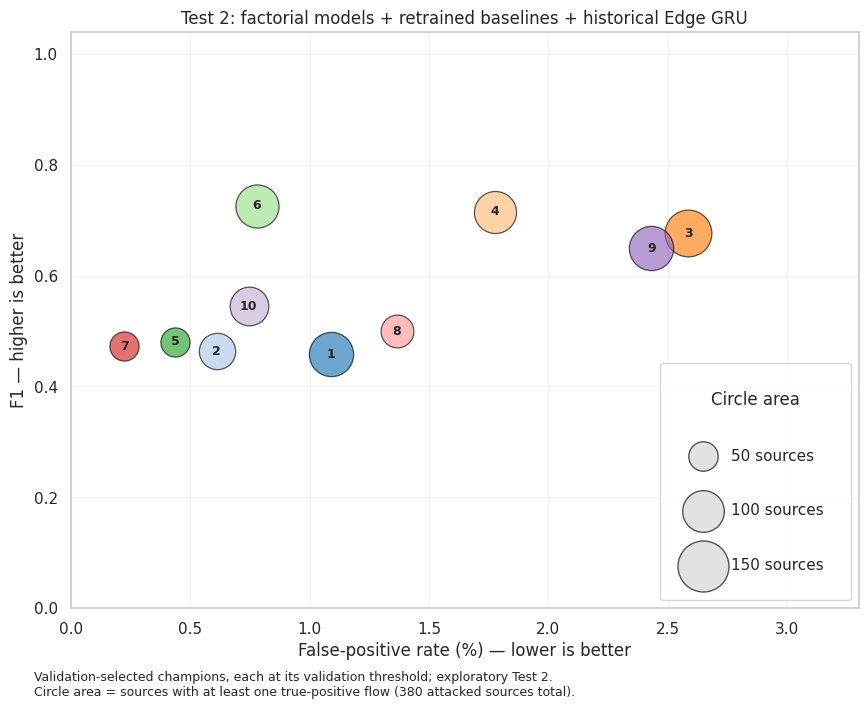

,plot_id,model,origin,seed,threshold,F1,Recall,FPR_percent,sources_detected,attacked_sources
0,1,M0_P0,factorial retraining,2024,0.335859,0.458530,0.360886,1.089349,113,380
1,2,M0_P1,factorial retraining,123,0.312264,0.463877,0.338059,0.610443,76,380
2,3,M1_P0,factorial retraining,2024,0.582388,0.677492,0.771529,2.585610,126,380
3,4,M1_P1,factorial retraining,2024,0.376981,0.715693,0.751004,1.776312,102,380
4,5,M0_P0_param,factorial retraining,2024,0.650717,0.480890,0.343684,0.437767,49,380
5,6,M1_P0_param,factorial retraining,2024,0.783274,0.726545,0.657375,0.777705,107,380
6,7,MLP,retrained baseline,777,0.455980,0.472171,0.322581,0.223755,49,380
7,8,E-GraphSAGE,retrained baseline,2024,0.260274,0.499281,0.421584,1.365069,62,380
8,9,Edge GRU (historical NoX),historical baseline,99,0.350914,0.650233,0.710994,2.431437,113,380
9,10,Static GNN,retrained baseline,99,0.321047,0.545332,0.429482,0.744095,86,380


Guardado en: /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/run_20261025T033137_448823Z


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/nids-mitre")
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"
HIST = ROOT / "results_earlystopping"

INCLUDE_PARAMETER_MATCHED = True  # False para mostrar solo los cuatro M/P principales.

# 1. Baselines nuevos: excluir su Edge GRU.
baseline = pd.read_csv(
    BASE / "test2_champions.csv", float_precision="round_trip"
)
baseline = baseline.loc[
    baseline["model"].isin(["MLP", "E-GraphSAGE", "Static GNN"])
].copy()

assert set(baseline["model"]) == {"MLP", "E-GraphSAGE", "Static GNN"}
assert baseline["status"].eq("complete").all()
baseline["origin"] = "retrained baseline"

# 2. Factorial completo.
factorial = pd.read_csv(
    FACT / "test2_champions.csv", float_precision="round_trip"
)
factorial = factorial.loc[
    factorial["model"].str.match(r"^M[01]_P[01](?:_param)?$")
].copy()

if not INCLUDE_PARAMETER_MATCHED:
    factorial = factorial.loc[
        ~factorial["model"].str.endswith("_param")
    ].copy()

assert {"M0_P0", "M0_P1", "M1_P0", "M1_P1"} <= set(factorial["model"])
assert factorial["status"].eq("complete").all()
factorial["origin"] = "factorial retraining"

# 3. Campeón HISTÓRICO de Edge GRU NoX.
experiment = "EdgeGRU_NoX_BiasOn"
edge_csv = pd.read_csv(
    HIST / "test2_results" / f"test2_metrics_{experiment}.csv",
    float_precision="round_trip",
)
assert len(edge_csv) == 1
old = edge_csv.iloc[0]
seed = int(old["seed"])
assert seed == 99

# Calcular fuentes detectadas desde sus predicciones históricas guardadas.
cache = (
    ROOT / "results_comparison" / "temporal_operational_v1"
    / f"edge_gru_seed_{seed}_test2.npz"
)
assert cache.is_file(), f"Falta el caché histórico: {cache}"

with np.load(cache, allow_pickle=False) as saved:
    y = saved["labels"].copy()
    sources = saved["sources"].copy()
    probabilities = saved["probabilities"].copy()
    threshold = float(saved["threshold"])
    checkpoint_hash = str(saved["checkpoint_sha256"].item())

checkpoints = list(
    (HIST / "saved_models" / experiment).glob(
        f'{old["run_id"]}_*.pth'
    )
)
assert len(checkpoints) == 1
assert (
    hashlib.sha256(checkpoints[0].read_bytes()).hexdigest()
    == checkpoint_hash
)
assert len(y) == len(sources) == len(probabilities) == 2135957
assert int(y.sum()) == 103825

if "optimal_threshold" in old and pd.notna(old["optimal_threshold"]):
    assert np.isclose(
        threshold, float(old["optimal_threshold"]), rtol=0, atol=1e-8
    )

alert = probabilities > threshold
tp = int(((y == 1) & alert).sum())
fp = int(((y == 0) & alert).sum())
tn = int(((y == 0) & ~alert).sum())
fn = int(((y == 1) & ~alert).sum())

for key, value in [("TP", tp), ("FP", fp), ("TN", tn), ("FN", fn)]:
    assert value == int(old[key]), f"El caché histórico no coincide: {key}"

detected = int(np.unique(sources[(y == 1) & alert]).size)
attacked = int(np.unique(sources[y == 1]).size)

edge = pd.DataFrame([dict(
    model="Edge GRU (historical NoX)",
    origin="historical baseline",
    seed=seed,
    threshold=threshold,
    F1=float(old["F1"]),
    FPR=float(old["FPR"]),
    Recall=float(old["Recall"]),
    sources_detected=detected,
    attacked_sources=attacked,
    flows=len(y),
    attacks=int(y.sum()),
)])

# 4. Tabla definitiva: sin ST-GNN histórico.
plot_data = pd.concat([factorial, baseline, edge], ignore_index=True)

order = [
    "M0_P0", "M0_P1", "M1_P0", "M1_P1",
    "M0_P0_param", "M1_P0_param",
    "MLP", "E-GraphSAGE", "Edge GRU (historical NoX)", "Static GNN",
]
present = set(plot_data["model"])
plot_data = (
    plot_data.set_index("model")
    .loc[[name for name in order if name in present]]
    .reset_index()
)

assert plot_data["model"].is_unique
assert plot_data["flows"].eq(2135957).all()
assert plot_data["attacks"].eq(103825).all()
assert plot_data["attacked_sources"].eq(380).all()
assert np.isfinite(
    plot_data[["F1", "FPR", "sources_detected"]].to_numpy()
).all()
assert plot_data["F1"].between(0, 1).all()
assert plot_data["FPR"].between(0, 1).all()
assert plot_data["sources_detected"].between(0, 380).all()

plot_data["plot_id"] = np.arange(1, len(plot_data) + 1)
plot_data["FPR_percent"] = 100 * plot_data["FPR"]
plot_data["seed"] = plot_data["seed"].astype(int)

# 5. Gráfico: área proporcional al número de fuentes detectadas.
AREA_PER_SOURCE = 9.0
palette = plt.get_cmap("tab20")
colors = {
    name: palette(i)
    for i, name in enumerate(plot_data["model"])
}

fig, ax = plt.subplots(figsize=(15, 8))

for _, row in plot_data.sort_values(
    "sources_detected", ascending=False
).iterrows():
    ax.scatter(
        row["FPR_percent"], row["F1"],
        s=AREA_PER_SOURCE * row["sources_detected"],
        color=colors[row["model"]],
        alpha=0.65,
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        str(int(row["plot_id"])),
        (row["FPR_percent"], row["F1"]),
        ha="center", va="center",
        fontsize=9, fontweight="bold",
        zorder=4,
    )

handles = []
for _, row in plot_data.iterrows():
    name = (
        "M1_P1 (ST-GNN, corrected memory)"
        if row["model"] == "M1_P1"
        else row["model"]
    )
    label = (
        f'{int(row["plot_id"]):2d}. {name}\n'
        f'     seed {row["seed"]} | '
        f'{int(row["sources_detected"])} sources'
    )
    handles.append(Line2D(
        [], [], linestyle="", marker="o", markersize=8,
        color=colors[row["model"]],
        markeredgecolor="black",
        label=label,
    ))

legend = ax.legend(
    handles=handles,
    loc="upper left", bbox_to_anchor=(1.02, 1),
    frameon=False, fontsize=9, labelspacing=0.85,
)
ax.add_artist(legend)

size_handles = [
    ax.scatter(
        [], [],
        s=AREA_PER_SOURCE * count,
        color="lightgray", edgecolor="black",
        alpha=0.65, label=f"{count} sources",
    )
    for count in (50, 100, 150)
]
ax.legend(
    handles=size_handles,
    title="Circle area",
    loc="lower right",
    labelspacing=2.6,
    borderpad=1.8,
)

ax.set_xlabel("False-positive rate (%) — lower is better")
ax.set_ylabel("F1 — higher is better")
ax.set_title(
    "Test 2: factorial models + retrained baselines + historical Edge GRU"
)
ax.set_xlim(
    0, max(3.3, float(plot_data["FPR_percent"].max()) * 1.15)
)
ax.set_ylim(0, 1.04)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)

fig.subplots_adjust(right=0.65, bottom=0.16)
fig.text(
    0.1, 0.05,
    "Validation-selected champions, each at its validation threshold; "
    "exploratory Test 2.\n"
    "Circle area = sources with at least one true-positive flow "
    "(380 attacked sources total).",
    ha="left", fontsize=9,
)

# 6. Guardar la figura y los datos en una carpeta nueva.
out = (
    ROOT / "results_comparison" / "primary_comparison_figures"
    / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
)
out.mkdir(parents=True, exist_ok=False)

for extension in ("png", "pdf"):
    fig.savefig(
        out / f"test2_f1_fpr_sources.{extension}",
        dpi=220, bbox_inches="tight",
    )

plot_data.to_csv(out / "test2_plot_data.csv", index=False)
plt.show()

display(plot_data[[
    "plot_id", "model", "origin", "seed", "threshold",
    "F1", "Recall", "FPR_percent",
    "sources_detected", "attacked_sources",
]].round(6))

print("Guardado en:", out)



Umbral CSV histórico: 0.35091423999999999
Umbral histórico utilizado: 0.35091423988342285 (NPZ histórico)
Umbral reentrenado: 0.35091423988342285
Diferencia CSV/reentrenado: 1.1657713683277393e-10
Alertas diferentes en Test 1: 0


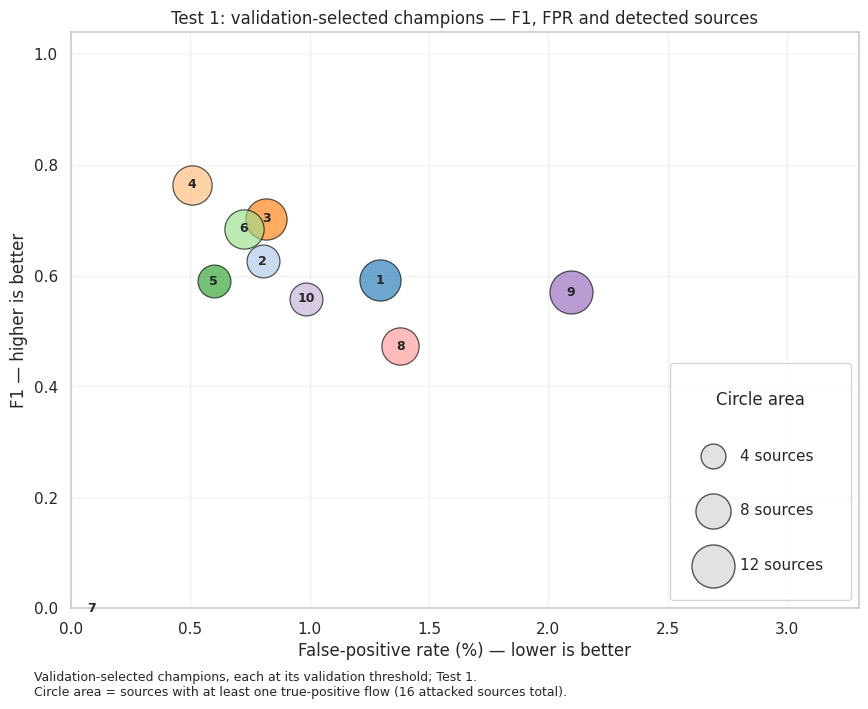

,plot_id,model,origin,seed,threshold,F1,Recall,FPR_percent,sources_detected,attacked_sources
0,1,M0_P0,factorial retraining,2024,0.335859,0.592157,0.718987,1.294058,11,16
1,2,M0_P1,factorial retraining,123,0.312264,0.626787,0.657542,0.803740,7,16
2,3,M1_P0,factorial retraining,2024,0.582388,0.703090,0.785090,0.817552,11,16
3,4,M1_P1,factorial retraining,2024,0.376981,0.764507,0.790332,0.505724,10,16
4,5,M0_P0_param,factorial retraining,2024,0.650717,0.589763,0.555329,0.598157,7,16
5,6,M1_P0_param,factorial retraining,2024,0.783274,0.685040,0.727432,0.722994,10,16
6,7,MLP,retrained baseline,777,0.455980,0.000000,0.000000,0.084996,0,16
7,8,E-GraphSAGE,retrained baseline,2024,0.260274,0.473224,0.544263,1.379054,9,16
8,9,Edge GRU (historical NoX),historical; identical weights and Test 1 alert...,99,0.350914,0.571069,0.858765,2.095673,12,16
9,10,Static GNN,retrained baseline,99,0.321047,0.558703,0.597263,0.986480,7,16


Guardado en: /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/run_20261025T034403_669916Z


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/nids-mitre")
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"
HIST = ROOT / "results_earlystopping"

INCLUDE_PARAMETER_MATCHED = True  # False para mostrar solo los cuatro M/P principales.

import torch


def test1_of_validation_champions(folder):
    champions = pd.read_csv(folder / "test2_champions.csv")
    results = pd.read_csv(
        folder / "test1_all_seeds.csv",
        float_precision="round_trip",
    )
    selected = champions[["model", "seed"]].merge(
        results,
        on=["model", "seed"],
        how="left",
        validate="one_to_one",
    )
    assert selected["status"].eq("complete").all()
    return selected


base_all = test1_of_validation_champions(BASE)
baseline = base_all.loc[
    base_all["model"].isin(["MLP", "E-GraphSAGE", "Static GNN"])
].copy()
baseline["origin"] = "retrained baseline"

factorial = test1_of_validation_champions(FACT)
factorial = factorial.loc[
    factorial["model"].str.match(r"^M[01]_P[01](?:_param)?$")
].copy()
if not INCLUDE_PARAMETER_MATCHED:
    factorial = factorial.loc[
        ~factorial["model"].str.endswith("_param")
    ].copy()
factorial["origin"] = "factorial retraining"

# Edge GRU histórico: mismo campeón histórico, semilla 99.
experiment = "EdgeGRU_NoX_BiasOn"
historical = pd.read_csv(
    HIST / "test1_results" / f"test1_metrics_{experiment}.csv",
    float_precision="round_trip",
)
historical = historical.loc[historical["seed"].eq(99)]
assert len(historical) == 1
old = historical.iloc[0]

new_edge = base_all.loc[
    base_all["model"].eq("Edge GRU") & base_all["seed"].eq(99)
].copy()
assert len(new_edge) == 1

# Para reutilizar el conteo de fuentes de Test 1, exigir pesos idénticos.
old_paths = list(
    (HIST / "saved_models" / experiment).glob(
        f'{old["run_id"]}_*.pth'
    )
)
assert len(old_paths) == 1
old_state = torch.load(
    old_paths[0], map_location="cpu", weights_only=True
)
new_state = torch.load(
    BASE / "edge_gru" / "seed_99" / "checkpoint.pth",
    map_location="cpu", weights_only=True,
)
assert old_state.keys() == new_state.keys()
assert all(
    torch.equal(old_state[key], new_state[key])
    for key in old_state
), "Los pesos difieren: hay que calcular sources desde el checkpoint histórico."


import json

threshold_csv = float(old["optimal_threshold"])
threshold_new = float(new_edge.iloc[0]["threshold"])
threshold_hist = threshold_csv
threshold_source = "CSV histórico"

threshold_file = (
    HIST / "logs" / experiment / f"thresholds_{experiment}.npz"
)
if threshold_file.exists():
    with np.load(threshold_file, allow_pickle=False) as saved:
        if "seed_99" in saved.files:
            threshold_hist = float(saved["seed_99"])
            threshold_source = "NPZ histórico"

print(f"Umbral CSV histórico: {threshold_csv:.17g}")
print(
    f"Umbral histórico utilizado: {threshold_hist:.17g} "
    f"({threshold_source})"
)
print(f"Umbral reentrenado: {threshold_new:.17g}")
print(
    "Diferencia CSV/reentrenado:",
    abs(threshold_csv - threshold_new),
)

# Los pesos idénticos ya se comprobaron en el bloque anterior.
checkpoint = BASE / "edge_gru" / "seed_99" / "checkpoint.pth"
cache = BASE / "edge_gru" / "seed_99" / "test1_scores.npz"

with np.load(cache, allow_pickle=False) as saved:
    scores = saved["probabilities"].copy()
    metadata = json.loads(str(saved["metadata"].item()))

assert len(scores) == 191679 and np.isfinite(scores).all()
assert metadata["split"] == "test1"
assert int(metadata["seed"]) == 99
assert metadata["checkpoint_sha256"] == hashlib.sha256(
    checkpoint.read_bytes()
).hexdigest()
assert np.isclose(
    float(metadata["threshold"]), threshold_new,
    rtol=0, atol=1e-12,
)

historical_alerts = scores > threshold_hist
retrained_alerts = scores > threshold_new
different_alerts = int(np.count_nonzero(
    historical_alerts != retrained_alerts
))

print("Alertas diferentes en Test 1:", different_alerts)
assert different_alerts == 0, (
    "Los umbrales producen alertas distintas: "
    "hay que recalcular las fuentes del histórico."
)

for key in ("TP", "FP", "TN", "FN"):
    assert int(old[key]) == int(new_edge.iloc[0][key])

edge = new_edge.copy()
edge["model"] = "Edge GRU (historical NoX)"
edge["origin"] = "historical; identical weights and Test 1 alerts verified"
for key in ("F1", "FPR", "Recall"):
    edge[key] = float(old[key])
edge["threshold"] = threshold_hist



plot_data = pd.concat([factorial, baseline, edge], ignore_index=True)
order = [
    "M0_P0", "M0_P1", "M1_P0", "M1_P1",
    "M0_P0_param", "M1_P0_param",
    "MLP", "E-GraphSAGE", "Edge GRU (historical NoX)", "Static GNN",
]
present = set(plot_data["model"])
plot_data = (
    plot_data.set_index("model")
    .loc[[name for name in order if name in present]]
    .reset_index()
)

assert plot_data["model"].is_unique
assert plot_data["flows"].eq(191679).all()
assert plot_data["attacks"].eq(3434).all()
assert plot_data["attacked_sources"].eq(16).all()

plot_data["plot_id"] = np.arange(1, len(plot_data) + 1)
plot_data["FPR_percent"] = 100 * plot_data["FPR"]
plot_data["seed"] = plot_data["seed"].astype(int)


# 5. Gráfico: área proporcional al número de fuentes detectadas.
AREA_PER_SOURCE = 80.0
palette = plt.get_cmap("tab20")
colors = {
    name: palette(i)
    for i, name in enumerate(plot_data["model"])
}

fig, ax = plt.subplots(figsize=(15, 8))

for _, row in plot_data.sort_values(
    "sources_detected", ascending=False
).iterrows():
    ax.scatter(
        row["FPR_percent"], row["F1"],
        s=AREA_PER_SOURCE * row["sources_detected"],
        color=colors[row["model"]],
        alpha=0.65,
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        str(int(row["plot_id"])),
        (row["FPR_percent"], row["F1"]),
        ha="center", va="center",
        fontsize=9, fontweight="bold",
        zorder=4,
    )

handles = []
for _, row in plot_data.iterrows():
    name = (
        "M1_P1 (ST-GNN, corrected memory)"
        if row["model"] == "M1_P1"
        else row["model"]
    )
    label = (
        f'{int(row["plot_id"]):2d}. {name}\n'
        f'     seed {row["seed"]} | '
        f'{int(row["sources_detected"])} sources'
    )
    handles.append(Line2D(
        [], [], linestyle="", marker="o", markersize=8,
        color=colors[row["model"]],
        markeredgecolor="black",
        label=label,
    ))

legend = ax.legend(
    handles=handles,
    loc="upper left", bbox_to_anchor=(1.02, 1),
    frameon=False, fontsize=9, labelspacing=0.85,
)
ax.add_artist(legend)

size_handles = [
    ax.scatter(
        [], [],
        s=AREA_PER_SOURCE * count,
        color="lightgray", edgecolor="black",
        alpha=0.65, label=f"{count} sources",
    )
    for count in (4, 8, 12)
]
ax.legend(
    handles=size_handles,
    title="Circle area",
    loc="lower right",
    labelspacing=2.6,
    borderpad=1.8,
)

ax.set_xlabel("False-positive rate (%) — lower is better")
ax.set_ylabel("F1 — higher is better")
ax.set_title(
    "Test 1: validation-selected champions — F1, FPR and detected sources"
)
ax.set_xlim(
    0, max(3.3, float(plot_data["FPR_percent"].max()) * 1.15)
)
ax.set_ylim(0, 1.04)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)

fig.subplots_adjust(right=0.65, bottom=0.16)
fig.text(
    0.1, 0.05,
    "Validation-selected champions, each at its validation threshold; Test 1.\n"
    "Circle area = sources with at least one true-positive flow "
    "(16 attacked sources total).",
    ha="left", fontsize=9,
)

# 6. Guardar la figura y los datos en una carpeta nueva.
out = (
    ROOT / "results_comparison" / "primary_comparison_figures"
    / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
)
out.mkdir(parents=True, exist_ok=False)

for extension in ("png", "pdf"):
    fig.savefig(
        out / f"test1_f1_fpr_sources.{extension}",
        dpi=220, bbox_inches="tight",
    )

plot_data.to_csv(out / "test1_plot_data.csv", index=False)
plt.show()

display(plot_data[[
    "plot_id", "model", "origin", "seed", "threshold",
    "F1", "Recall", "FPR_percent",
    "sources_detected", "attacked_sources",
]].round(6))

print("Guardado en:", out)



In [ ]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import torch

from utils.datasets import NF_IDS_Dataset
from utils.models import EdgeGRU_Baseline_NoX

ROOT = Path("/content/drive/MyDrive/nids-mitre")
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"
HIST = ROOT / "results_earlystopping"

INCLUDE_PARAMETER_MATCHED = True
SEEDS = {42, 99, 123, 777, 2024}
torch.set_num_threads(1)

# Baselines nuevos, excluyendo Edge GRU y ST-GNN históricos.
baselines = pd.read_csv(
    BASE / "test1_all_seeds.csv", float_precision="round_trip"
)
baselines = baselines.loc[
    baselines["model"].isin(["MLP", "E-GraphSAGE", "Static GNN"])
].copy()

assert set(baselines["model"]) == {"MLP", "E-GraphSAGE", "Static GNN"}
assert baselines["status"].eq("complete").all()
baselines["origin"] = "retrained baseline"

# Factoriales: M1_P1 ya representa ST-GNN con memoria corregida.
factorial = pd.read_csv(
    FACT / "test1_all_seeds.csv", float_precision="round_trip"
)
factorial = factorial.loc[
    factorial["model"].str.match(r"^M[01]_P[01](?:_param)?$")
    ].copy()

assert {"M0_P0", "M0_P1", "M1_P0", "M1_P1"} <= set(factorial["model"])
assert factorial["status"].eq("complete").all()
factorial["origin"] = "factorial retraining"

# Edge GRU NoX histórico: usar sus cinco corridas originales.
experiment = "EdgeGRU_NoX_BiasOn"
historical = pd.read_csv(
    HIST / "test1_results" / f"test1_metrics_{experiment}.csv",
    float_precision="round_trip",
)
assert len(historical) == 5
assert set(historical["seed"].astype(int)) == SEEDS
assert historical["seed"].is_unique

manifest = json.loads((FACT / "manifest.json").read_text())
split = manifest["splits"]["test1"]
dataset = NF_IDS_Dataset(
    root_dir=split["root"], split=split["directory"]
)
assert len(dataset) == split["graphs"]

# Leer grafos una vez y conservar el orden temporal.
print("Leyendo grafos de Test 1; no se realiza entrenamiento.", flush=True)
graphs = []
for i in range(len(dataset)):
    graph = dataset[i].cpu()
    if graph.x.shape[0] > 0:
        graphs.append(graph)
    if (i + 1) % 100 == 0:
        print(f"Leídos {i + 1}/{len(dataset)} grafos", flush=True)

labels = np.concatenate([
    g.y.numpy().reshape(-1) for g in graphs
]).astype(np.int8)
sources = np.concatenate([
    g.global_node_ids[g.edge_index[0]].numpy() for g in graphs
])

assert len(labels) == 191679
assert int(labels.sum()) == 3434
assert np.unique(sources[labels == 1]).size == 16

# El NPZ conserva el umbral efectivo histórico, si está disponible.
threshold_file = (
    HIST / "logs" / experiment / f"thresholds_{experiment}.npz"
)
thresholds = {}
if threshold_file.exists():
    with np.load(threshold_file, allow_pickle=False) as saved:
        thresholds = {
            key: float(saved[key].item()) for key in saved.files
        }

edge_rows = []
for _, old in historical.iterrows():
    seed = int(old["seed"])
    threshold = thresholds.get(
        f"seed_{seed}", float(old["optimal_threshold"])
    )
    paths = list(
        (HIST / "saved_models" / experiment).glob(
            f'{old["run_id"]}_*.pth'
        )
    )
    assert len(paths) == 1, (seed, paths)
    checkpoint = paths[0]

    model = EdgeGRU_Baseline_NoX(**manifest["model_params"]).cpu()
    model.load_state_dict(
        torch.load(checkpoint, map_location="cpu", weights_only=True),
        strict=True,
    )
    model.eval()
    model.reset_memory()

    print(f"Evaluando Edge GRU histórico, seed {seed}...", flush=True)
    with torch.no_grad():
        probabilities = np.concatenate([
            torch.sigmoid(
                model(
                    g.x, g.edge_index, g.edge_attr, g.global_node_ids
                ).reshape(-1)
            ).numpy()
            for g in graphs
        ])

    assert len(probabilities) == len(labels)
    assert np.isfinite(probabilities).all()
    alert = probabilities > threshold

    counts = {
        "TP": int(((labels == 1) & alert).sum()),
        "FP": int(((labels == 0) & alert).sum()),
        "TN": int(((labels == 0) & ~alert).sum()),
        "FN": int(((labels == 1) & ~alert).sum()),
    }
    assert all(counts[k] == int(old[k]) for k in counts), (
        f"Seed {seed}: los conteos no coinciden con el histórico. "
        f"Revisar umbral/entorno. Actual={counts}; "
        f"histórico={ {k: int(old[k]) for k in counts} }"
    )

    detected = int(
        np.unique(sources[(labels == 1) & alert]).size
    )
    edge_rows.append({
        "model": "Edge GRU (historical NoX)",
        "seed": seed,
        "origin": "historical baseline",
        "F1": float(old["F1"]),
        "FPR": float(old["FPR"]),
        "sources_detected": detected,
        "attacked_sources": 16,
        "flows": len(labels),
        "attacks": int(labels.sum()),
        "threshold": threshold,
        "run_id": old["run_id"],
        "checkpoint_sha256": hashlib.sha256(
            checkpoint.read_bytes()
        ).hexdigest(),
    })
    print(
        f'  Verificado: F1={old["F1"]:.6f}; '
        f"fuentes detectadas={detected}",
        flush=True,
    )
    model.reset_memory()
    del model, probabilities

mean_seed_data = pd.concat(
    [factorial, baselines, pd.DataFrame(edge_rows)],
    ignore_index=True,
)

assert not mean_seed_data.duplicated(["model", "seed"]).any()
assert mean_seed_data["flows"].eq(191679).all()
assert mean_seed_data["attacks"].eq(3434).all()
assert mean_seed_data["attacked_sources"].eq(16).all()

for name, group in mean_seed_data.groupby("model"):
    assert len(group) == 5, name
    assert set(group["seed"].astype(int)) == SEEDS, name

assert np.isfinite(
    mean_seed_data[["F1", "FPR", "sources_detected"]].to_numpy()
).all()

mean_seed_data["FPR_percent"] = 100 * mean_seed_data["FPR"]

# Media y desviación estándar muestral entre las cinco semillas.
mean_summary = mean_seed_data.groupby("model", sort=False).agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    FPR_mean_percent=("FPR_percent", "mean"),
    FPR_std_percent=("FPR_percent", "std"),
    sources_mean=("sources_detected", "mean"),
    sources_std=("sources_detected", "std"),
    n_seeds=("seed", "nunique"),
)

order = [
    "M0_P0", "M0_P1", "M1_P0", "M1_P1",
    "M0_P0_param", "M1_P0_param",
    "MLP", "E-GraphSAGE", "Edge GRU (historical NoX)", "Static GNN",
]
mean_summary = mean_summary.loc[
    [name for name in order if name in mean_summary.index]
].reset_index()
mean_summary["plot_id"] = np.arange(1, len(mean_summary) + 1)

print("Listo: ejecutar la celda del gráfico.")


Leyendo grafos de Test 1; no se realiza entrenamiento.
Leídos 100/429 grafos
Leídos 200/429 grafos
Leídos 300/429 grafos
Leídos 400/429 grafos
Evaluando Edge GRU histórico, seed 42...
  Verificado: F1=0.495240; fuentes detectadas=10
Evaluando Edge GRU histórico, seed 123...
  Verificado: F1=0.186220; fuentes detectadas=11
Evaluando Edge GRU histórico, seed 777...
  Verificado: F1=0.583351; fuentes detectadas=12
Evaluando Edge GRU histórico, seed 2024...
  Verificado: F1=0.308581; fuentes detectadas=10
Evaluando Edge GRU histórico, seed 99...
  Verificado: F1=0.571069; fuentes detectadas=12
Listo: ejecutar la celda del gráfico.


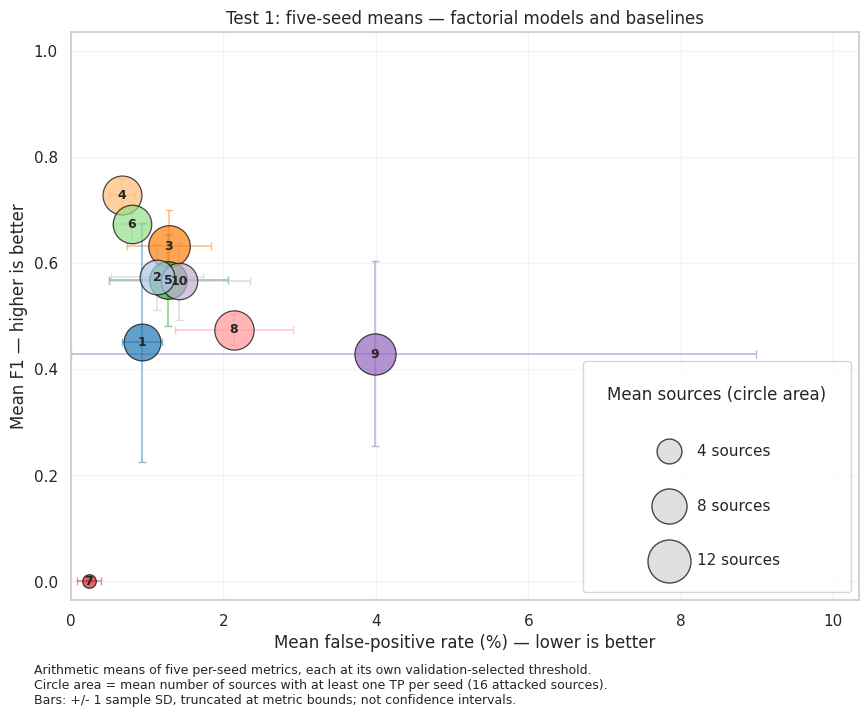

,model,F1_mean,F1_std,FPR_mean_percent,FPR_std_percent,sources_mean,sources_std,n_seeds,plot_id
0,M0_P0,0.450083,0.224789,0.934952,0.262549,8.8,1.483240,5,1
1,M0_P1,0.573031,0.061668,1.126829,0.603961,7.8,1.303840,5,2
2,M1_P0,0.630971,0.067817,1.285452,0.545908,11.2,0.836660,5,3
3,M1_P1,0.728431,0.028807,0.672422,0.170397,9.8,0.836660,5,4
4,M0_P0_param,0.568004,0.086490,1.277590,0.780733,9.2,2.167948,5,5
5,M1_P0_param,0.673254,0.036259,0.796940,0.240123,9.6,0.547723,5,6
6,MLP,0.001241,0.001711,0.235332,0.151786,1.2,1.643168,5,7
7,E-GraphSAGE,0.474459,0.029064,2.135196,0.774496,10.0,1.224745,5,8
8,Edge GRU (historical NoX),0.428892,0.174527,3.986294,4.998298,11.0,1.000000,5,9
9,Static GNN,0.565044,0.072783,1.421870,0.922534,8.6,1.516575,5,10


Guardado en: /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/test1_means_20261025T040358_071804Z


In [ ]:
from datetime import datetime, timezone
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

SHOW_STD = True
AREA_PER_SOURCE = 80.0

summary = mean_summary.copy()
palette = plt.get_cmap("tab20")
colors = {
    name: palette(i)
    for i, name in enumerate(summary["model"])
}

fig, ax = plt.subplots(figsize=(15, 8))

for _, row in summary.sort_values(
    "sources_mean", ascending=False
).iterrows():
    x = float(row["FPR_mean_percent"])
    y = float(row["F1_mean"])
    color = colors[row["model"]]

    if SHOW_STD:
        # Recortar las barras en los límites válidos de cada métrica.
        # La tabla conserva las desviaciones completas.
        sx = float(row["FPR_std_percent"])
        sy = float(row["F1_std"])
        ax.errorbar(
            x, y,
            xerr=[[min(x, sx)], [min(100 - x, sx)]],
            yerr=[[min(y, sy)], [min(1 - y, sy)]],
            fmt="none",
            capsize=3,
            ecolor=color,
            alpha=0.5,
            linewidth=1.2,
            zorder=2,
        )

    ax.scatter(
        x, y,
        s=AREA_PER_SOURCE * row["sources_mean"],
        color=color,
        alpha=0.7,
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        str(int(row["plot_id"])),
        (x, y),
        ha="center", va="center",
        fontsize=9, fontweight="bold",
        zorder=4,
    )

handles = []
for _, row in summary.iterrows():
    name = (
        "M1_P1 (ST-GNN, corrected memory)"
        if row["model"] == "M1_P1"
        else row["model"]
    )
    label = (
        f'{int(row["plot_id"]):2d}. {name}\n'
        f'     5 seeds | mean sources: {row["sources_mean"]:.1f}'
    )
    handles.append(Line2D(
        [], [],
        linestyle="", marker="o", markersize=8,
        color=colors[row["model"]],
        markeredgecolor="black",
        label=label,
    ))

legend = ax.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=9,
    labelspacing=0.85,
)
ax.add_artist(legend)

size_handles = [
    ax.scatter(
        [], [],
        s=AREA_PER_SOURCE * count,
        color="lightgray",
        edgecolor="black",
        alpha=0.7,
        label=f"{count} sources",
    )
    for count in (4, 8, 12)
]
ax.legend(
    handles=size_handles,
    title="Mean sources (circle area)",
    loc="lower right",
    labelspacing=2.6,
    borderpad=1.6,
)

right = summary["FPR_mean_percent"].copy()
if SHOW_STD:
    right += summary["FPR_std_percent"]

ax.set_xlim(0, max(1.0, float(right.max()) * 1.15))
ax.set_ylim(-0.035, 1.035)
ax.set_xlabel("Mean false-positive rate (%) — lower is better")
ax.set_ylabel("Mean F1 — higher is better")
ax.set_title(
    "Test 1: five-seed means — factorial models and baselines"
)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.65, bottom=0.17)

note = (
    "Bars: +/- 1 sample SD, truncated at metric bounds; "
    "not confidence intervals."
    if SHOW_STD else
    "Between-seed SD is reported in the table; bars are hidden."
)
fig.text(
    0.1, 0.04,
    "Arithmetic means of five per-seed metrics, each at its own "
    "validation-selected threshold.\n"
    "Circle area = mean number of sources with at least one TP "
    "per seed (16 attacked sources).\n" + note,
    ha="left",
    fontsize=9,
)

out = (
    ROOT / "results_comparison" / "primary_comparison_figures"
    / datetime.now(timezone.utc).strftime(
        "test1_means_%Y%m%dT%H%M%S_%fZ"
    )
)
out.mkdir(parents=True, exist_ok=False)

for extension in ("png", "pdf"):
    fig.savefig(
        out / f"test1_mean_bubbles.{extension}",
          dpi=220,
        bbox_inches="tight",
    )

summary.to_csv(out / "test1_mean_summary.csv", index=False)
mean_seed_data.to_csv(
    out / "test1_individual_seed_data.csv", index=False
)

plt.show()
display(summary.round(6))
print("Guardado en:", out)


The following figures extend the earlier Test 1 and Test 2 comparisons with the temporal MLP baseline results.


EdgeGRU histórico: conteos leídos de /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/test1_means_20261025T040358_071804Z/test1_individual_seed_data.csv


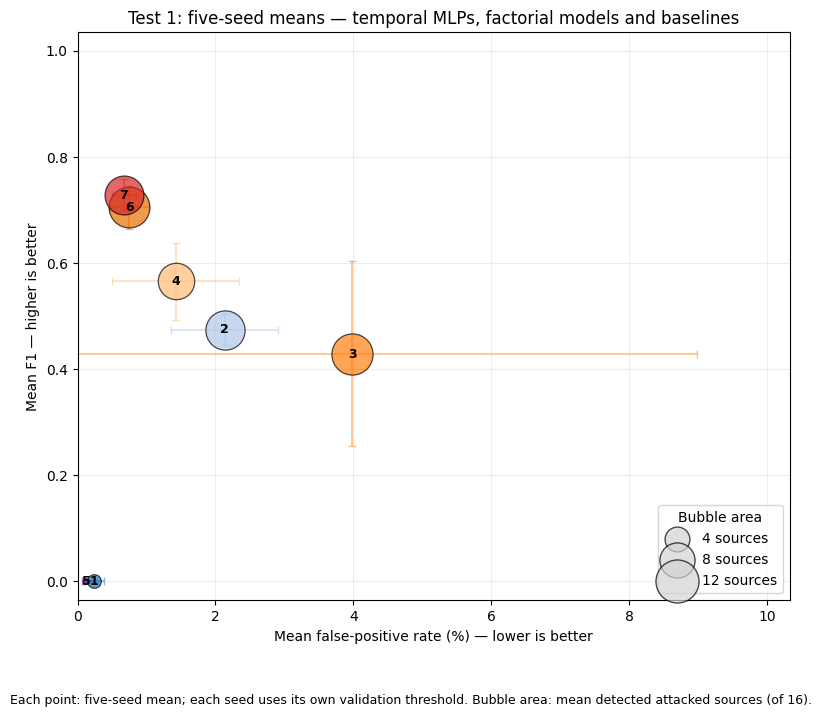

,model,F1_mean,F1_std,FPR_mean_percent,FPR_std_percent,sources_mean,sources_std,n_seeds,plot_id
0,MLP,0.00124,0.00171,0.23533,0.15179,1.2,1.64317,5,1
1,E-GraphSAGE,0.47446,0.02906,2.13520,0.77450,10.0,1.22474,5,2
2,Edge GRU (historical NoX),0.42889,0.17453,3.98629,4.99830,11.0,1.00000,5,3
3,Static GNN,0.56504,0.07278,1.42187,0.92253,8.6,1.51658,5,4
4,Global traffic MLP-GRU,0.00021,0.00046,0.12728,0.06694,0.2,0.44721,5,5
5,Host history MLP-GRU,0.70480,0.04098,0.75030,0.28263,10.8,1.48324,5,6
6,M1_P1,0.72843,0.02881,0.67242,0.17040,9.8,0.83666,5,7


Guardado en: /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/test1_temporal_mlp_means_20261027T133036_658134Z


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/nids-mitre")
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"
NEW = ROOT / "results_temporal_mlp_global_host_factorial_protocol_v1"
HIST = ROOT / "results_earlystopping"

SEEDS = {42, 99, 123, 777, 2024}
INCLUDE_PARAMETER_MATCHED = True
SHOW_STD = True  # True: mostrar ±1 desviación estándar en los ejes.
AREA_PER_SOURCE = 80.0

# Confirmar que los resultados usan los mismos grafos y la misma regla de umbral.
reference = json.loads((FACT / "manifest.json").read_text())
for folder in (BASE, NEW):
    run_manifest = json.loads((folder / "manifest.json").read_text())
    assert (
        run_manifest["splits"]["test1"]["dataset_sha256"]
        == reference["splits"]["test1"]["dataset_sha256"]
    ), folder
    assert run_manifest["threshold_rule"] == reference["threshold_rule"], folder

# Reutilizar fuentes detectadas de EdgeGRU histórico si el gráfico previo
# ya las calculó y guardó.
cache_files = sorted(
    (ROOT / "results_comparison" / "primary_comparison_figures").glob(
        "test1_means_*/test1_individual_seed_data.csv"
    )
)
edge = None

if cache_files:
    old_plot = pd.read_csv(cache_files[-1], float_precision="round_trip")
    candidate = old_plot.loc[
        old_plot["model"].eq("Edge GRU (historical NoX)")
    ].copy()
    if len(candidate) == 5 and set(candidate["seed"].astype(int)) == SEEDS:
        edge = candidate
        print("EdgeGRU histórico: conteos leídos de", cache_files[-1])

# Si no existe ese archivo, inferir los cinco checkpoints históricos.
if edge is None:
    import torch

    for folder in (
        "/content/temporalgnn-nids-temporal-mlp-utils/code/python",
        "/content/temporalgnn-nids-factorial-utils/code/python",
        "/content/temporalgnn-nids-baseline-retraining/code/python",
    ):
        if (Path(folder) / "utils/models.py").is_file():
            sys.path.insert(0, folder)
            break

    from utils.datasets import NF_IDS_Dataset
    from utils.models import EdgeGRU_Baseline_NoX

    torch.set_num_threads(1)

    split = reference["splits"]["test1"]
    dataset = NF_IDS_Dataset(
        root_dir=split["root"],
        split=split["directory"],
    )
    graphs = [dataset[i].cpu() for i in range(len(dataset))]
    graphs = [g for g in graphs if g.x.shape[0] > 0]

    y = np.concatenate(
        [g.y.reshape(-1).numpy() for g in graphs]
    ).astype(np.int8)
    sources = np.concatenate(
        [
            g.global_node_ids[g.edge_index[0]].numpy()
            for g in graphs
        ]
    )
    assert len(y) == 191679 and int(y.sum()) == 3434

    historical = pd.read_csv(
        HIST
        / "test1_results"
        / "test1_metrics_EdgeGRU_NoX_BiasOn.csv",
        float_precision="round_trip",
    )
    threshold_file = (
        HIST
        / "logs"
        / "EdgeGRU_NoX_BiasOn"
        / "thresholds_EdgeGRU_NoX_BiasOn.npz"
    )
    with np.load(threshold_file, allow_pickle=False) as saved:
        thresholds = {
            key: float(saved[key])
            for key in saved.files
        }

    rows = []
    for _, old in historical.iterrows():
        seed = int(old["seed"])
        threshold = thresholds[f"seed_{seed}"]

        checkpoints = list(
            (
                HIST
                / "saved_models"
                / "EdgeGRU_NoX_BiasOn"
            ).glob(f'{old["run_id"]}_*.pth')
        )
        assert len(checkpoints) == 1, (seed, checkpoints)

        model = EdgeGRU_Baseline_NoX(
            **reference["model_params"]
        ).cpu().eval()
        model.load_state_dict(
            torch.load(
                checkpoints[0],
                map_location="cpu",
                weights_only=True,
            ),
            strict=True,
        )
        model.reset_memory()

        with torch.no_grad():
            probabilities = np.concatenate(
                [
                    torch.sigmoid(
                        model(
                            g.x,
                            g.edge_index,
                            g.edge_attr,
                            g.global_node_ids,
                        ).reshape(-1)
                    ).numpy()
                    for g in graphs
                ]
            )

        alert = probabilities > threshold
        counts = {
            "TP": int(((y == 1) & alert).sum()),
            "FP": int(((y == 0) & alert).sum()),
            "TN": int(((y == 0) & ~alert).sum()),
            "FN": int(((y == 1) & ~alert).sum()),
        }
        assert all(
            counts[key] == int(old[key])
            for key in counts
        ), (seed, counts)

        rows.append(
            {
                "model": "Edge GRU (historical NoX)",
                "seed": seed,
                "F1": float(old["F1"]),
                "FPR": float(old["FPR"]),
                "sources_detected": int(
                    np.unique(sources[(y == 1) & alert]).size
                ),
                "attacked_sources": 16,
                "flows": len(y),
                "attacks": int(y.sum()),
                "origin": "historical baseline",
                "run_id": old["run_id"],
                "checkpoint_sha256": hashlib.sha256(
                    checkpoints[0].read_bytes()
                ).hexdigest(),
            }
        )
        print("EdgeGRU histórico, semilla", seed, ": verificada")
        del model

    edge = pd.DataFrame(rows)

# Verificar también el archivo reutilizado contra CSV y checkpoints históricos.
historical = pd.read_csv(
    HIST
    / "test1_results"
    / "test1_metrics_EdgeGRU_NoX_BiasOn.csv",
    float_precision="round_trip",
)
for _, row in edge.iterrows():
    old = historical.loc[
        historical["seed"].eq(int(row["seed"]))
    ].iloc[0]

    assert str(row["run_id"]) == str(old["run_id"])
    assert np.isclose(
        float(row["F1"]), float(old["F1"]),
        rtol=0, atol=1e-12,
    )
    assert np.isclose(
        float(row["FPR"]), float(old["FPR"]),
        rtol=0, atol=1e-12,
    )

    paths = list(
        (
            HIST
            / "saved_models"
            / "EdgeGRU_NoX_BiasOn"
        ).glob(f'{old["run_id"]}_*.pth')
    )
    assert len(paths) == 1
    assert row["checkpoint_sha256"] == hashlib.sha256(
        paths[0].read_bytes()
    ).hexdigest()

# Baselines actuales, excepto EdgeGRU reentrenado.
base = pd.read_csv(
    BASE / "test1_all_seeds.csv",
    float_precision="round_trip",
)
base = base.loc[
    base["model"].isin(["MLP", "E-GraphSAGE", "Static GNN"])
].copy()
base["origin"] = "retrained baseline"

# Ablaciones M/P; M1_P1 es la ST-GNN con memoria corregida.
factorial = pd.read_csv(
    FACT / "test1_all_seeds.csv",
    float_precision="round_trip",
)
factorial = factorial.loc[
    factorial["model"].str.match(r"^M[01]_P[01](?:_param)?$")
].copy()
if not INCLUDE_PARAMETER_MATCHED:
    factorial = factorial.loc[
        ~factorial["model"].str.endswith("_param")
    ].copy()
factorial["origin"] = "factorial retraining"

# Los dos MLP-GRU nuevos.
new = pd.read_csv(
    NEW / "test1_all_seeds.csv",
    float_precision="round_trip",
)
new = new.loc[
    new["model"].isin(
        ["Global traffic MLP-GRU", "Host history MLP-GRU"]
    )
].copy()
new["origin"] = "new temporal MLP"

assert set(new["model"]) == {
    "Global traffic MLP-GRU",
    "Host history MLP-GRU",
}
assert new["status"].eq("complete").all()

all_seeds = pd.concat(
    [factorial, base, edge, new],
    ignore_index=True,
)
assert not all_seeds.duplicated(["model", "seed"]).any()
assert all_seeds["flows"].eq(191679).all()
assert all_seeds["attacks"].eq(3434).all()
assert all_seeds["attacked_sources"].eq(16).all()

for name, group in all_seeds.groupby("model"):
    assert len(group) == 5
    assert set(group["seed"].astype(int)) == SEEDS, name

assert np.isfinite(
    all_seeds[["F1", "FPR", "sources_detected"]].to_numpy()
).all()

# Una burbuja por modelo: promedios de cinco semillas.
all_seeds["FPR_percent"] = 100 * all_seeds["FPR"]
summary = all_seeds.groupby("model", sort=False).agg(
    F1_mean=("F1", "mean"),
    F1_std=("F1", "std"),
    FPR_mean_percent=("FPR_percent", "mean"),
    FPR_std_percent=("FPR_percent", "std"),
    sources_mean=("sources_detected", "mean"),
    sources_std=("sources_detected", "std"),
    n_seeds=("seed", "nunique"),
)

order = [
    #"M0_P0", "M0_P1", "M1_P0", "M1_P1",
    #"M0_P0_param", "M1_P0_param",
    "MLP", "E-GraphSAGE",
    "Edge GRU (historical NoX)", "Static GNN",
    "Global traffic MLP-GRU", "Host history MLP-GRU", "M1_P1",
]
summary = summary.loc[
    [name for name in order if name in summary.index]
].reset_index()
summary["plot_id"] = np.arange(1, len(summary) + 1)

palette = plt.get_cmap("tab20")
colors = {
    name: palette(i)
    for i, name in enumerate(summary["model"])
}
colors["Global traffic MLP-GRU"] = "#7B2CBF"
colors["Host history MLP-GRU"] = "#E76F00"

fig, ax = plt.subplots(figsize=(15, 8))

for _, row in summary.sort_values(
    "sources_mean", ascending=False
).iterrows():
    x = row["FPR_mean_percent"]
    y_point = row["F1_mean"]

    if SHOW_STD:
        ax.errorbar(
            x, y_point,
            xerr=row["FPR_std_percent"],
            yerr=row["F1_std"],
            fmt="none",
            capsize=3,
            ecolor=colors[row["model"]],
            alpha=0.5,
            linewidth=1.2,
            zorder=2,
        )

    ax.scatter(
        x, y_point,
        s=AREA_PER_SOURCE * row["sources_mean"],
        color=colors[row["model"]],
        alpha=0.7,
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        str(int(row["plot_id"])),
        (x, y_point),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        zorder=4,
    )

handles = []
for _, row in summary.iterrows():
    name = (
        "M1_P1 (corrected ST-GNN)"
        if row["model"] == "M1_P1"
        else row["model"]
    )
    handles.append(
        Line2D(
            [], [],
            linestyle="",
            marker="o",
            markersize=8,
            color=colors[row["model"]],
            markeredgecolor="black",
            label=(
                f'{int(row["plot_id"]):2d}. {name} | '
                f'{row["sources_mean"]:.1f} mean sources'
            ),
        )
    )

legend = ax.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=9,
)
ax.add_artist(legend)

size_handles = [
    ax.scatter(
        [], [],
        s=AREA_PER_SOURCE * count,
        color="lightgray",
        edgecolor="black",
        alpha=0.7,
        label=f"{count} sources",
    )
    for count in (4, 8, 12)
]
ax.legend(
    handles=size_handles,
    title="Bubble area",
    loc="lower right",
)

right_edge = summary["FPR_mean_percent"] + (
    summary["FPR_std_percent"] if SHOW_STD else 0
)
ax.set_xlim(0, max(1.0, float(right_edge.max()) * 1.15))
ax.set_ylim(-0.035, 1.035)
ax.set_xlabel("Mean false-positive rate (%) — lower is better")
ax.set_ylabel("Mean F1 — higher is better")
ax.set_title(
    "Test 1: five-seed means — temporal MLPs, factorial models and baselines"
)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)

fig.subplots_adjust(right=0.60, bottom=0.17)
fig.text(
    0.08, 0.04,
    "Each point: five-seed mean; each seed uses its own validation threshold. "
    "Bubble area: mean detected attacked sources (of 16).",
    fontsize=9,
)

out = (
    ROOT
    / "results_comparison"
    / "primary_comparison_figures"
    / datetime.now(timezone.utc).strftime(
        "test1_temporal_mlp_means_%Y%m%dT%H%M%S_%fZ"
    )
)
out.mkdir(parents=True, exist_ok=False)

for extension in ("png", "pdf"):
    fig.savefig(
        out / f"test1_temporal_mlp_mean_bubbles.{extension}",
        dpi=220,
        bbox_inches="tight",
    )

summary.to_csv(out / "summary.csv", index=False)
all_seeds.to_csv(out / "per_seed.csv", index=False)

plt.show()
display(summary.round(5))
print("Guardado en:", out)

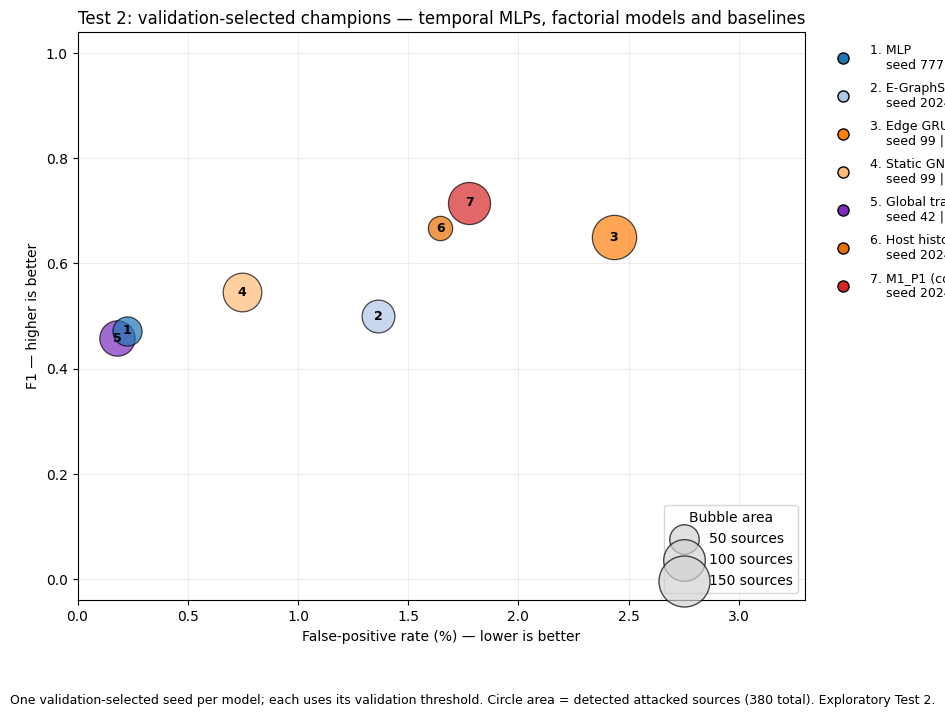

,plot_id,model,origin,seed,threshold,AUC-PR,F1,FPR_percent,sources_detected,attacked_sources
0,1,MLP,retrained baseline,777,0.455980,0.396098,0.472171,0.223755,49,380
1,2,E-GraphSAGE,retrained baseline,2024,0.260274,0.519386,0.499281,1.365069,62,380
2,3,Edge GRU (historical NoX),historical baseline,99,0.350914,0.730656,0.650233,2.431437,113,380
3,4,Static GNN,retrained baseline,99,0.321047,0.514817,0.545332,0.744095,86,380
4,5,Global traffic MLP-GRU,new temporal MLP,42,0.208754,0.398839,0.457637,0.180599,72,380
5,6,Host history MLP-GRU,new temporal MLP,2024,0.842090,0.662402,0.666939,1.646202,34,380
6,7,M1_P1,factorial retraining,2024,0.376981,0.798852,0.715693,1.776312,102,380


Guardado en: /content/drive/MyDrive/nids-mitre/results_comparison/primary_comparison_figures/test2_temporal_mlp_20261027T133109_796086Z


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/nids-mitre")
BASE = ROOT / "results_baseline_retraining_factorial_protocol_v1"
FACT = ROOT / "results_stgnn_memory_message_factorial_v1"
NEW = ROOT / "results_temporal_mlp_global_host_factorial_protocol_v1"
HIST = ROOT / "results_earlystopping"

INCLUDE_PARAMETER_MATCHED = True
AREA_PER_SOURCE = 9.0  # Test 2 tiene 380 fuentes atacantes.

# Verificar partición y regla de umbral.
reference = json.loads((FACT / "manifest.json").read_text())
for folder in (BASE, NEW):
    manifest = json.loads((folder / "manifest.json").read_text())
    assert (
        manifest["splits"]["test2"]["dataset_sha256"]
        == reference["splits"]["test2"]["dataset_sha256"]
    ), folder
    assert manifest["threshold_rule"] == reference["threshold_rule"], folder

# Baselines reentrenados, excepto EdgeGRU y ST-GNN.
base = pd.read_csv(
    BASE / "test2_champions.csv",
    float_precision="round_trip",
)
base = base.loc[
    base["model"].isin(["MLP", "E-GraphSAGE", "Static GNN"])
].copy()
base["origin"] = "retrained baseline"

# Factorial: M1_P1 corresponde a ST-GNN con memoria corregida.
factorial = pd.read_csv(
    FACT / "test2_champions.csv",
    float_precision="round_trip",
)
factorial = factorial.loc[
    factorial["model"].str.match(r"^M[01]_P[01](?:_param)?$")
].copy()
if not INCLUDE_PARAMETER_MATCHED:
    factorial = factorial.loc[
        ~factorial["model"].str.endswith("_param")
    ].copy()
factorial["origin"] = "factorial retraining"

# Nuevos MLP-GRU.
new = pd.read_csv(
    NEW / "test2_champions.csv",
    float_precision="round_trip",
)
new = new.loc[
    new["model"].isin(
        ["Global traffic MLP-GRU", "Host history MLP-GRU"]
    )
].copy()
new["origin"] = "new temporal MLP"
assert set(new["model"]) == {
    "Global traffic MLP-GRU",
    "Host history MLP-GRU",
}

# EdgeGRU histórico: evaluación guardada por el notebook factorial.
external_path = FACT / "external_edge_gru_operational.csv"
assert external_path.is_file(), (
    f"Falta {external_path}. Es necesario ejecutar la evaluación "
    "del EdgeGRU externo en el notebook factorial."
)
external = pd.read_csv(
    external_path,
    float_precision="round_trip",
)
external = external.loc[external["split"].eq("test2")].copy()
assert len(external) == 1
assert external["status"].eq("complete").all()
external_row = external.iloc[0]

# Comprobar que corresponde al checkpoint y las métricas históricas.
historical = pd.read_csv(
    HIST
    / "test2_results"
    / "test2_metrics_EdgeGRU_NoX_BiasOn.csv",
    float_precision="round_trip",
)
assert len(historical) == 1
old = historical.iloc[0]
assert int(external_row["seed"]) == int(old["seed"])

for key in ("TP", "FP", "TN", "FN"):
    assert int(external_row[key]) == int(old[key]), key

for key in ("F1", "FPR", "AUC-PR"):
    assert np.isclose(
        float(external_row[key]),
        float(old[key]),
        rtol=1e-4,
        atol=1e-4,
    ), key

audit = json.loads(
    (FACT / "external_edge_gru" / "test2_audit.json").read_text()
)
assert audit["status"] == "MATCH"
assert audit["run_id"] == str(old["run_id"])

paths = list(
    (HIST / "saved_models" / "EdgeGRU_NoX_BiasOn").glob(
        f'{old["run_id"]}_*.pth'
    )
)
assert len(paths) == 1
checkpoint_hash = hashlib.sha256(paths[0].read_bytes()).hexdigest()
assert checkpoint_hash == external_row["checkpoint_sha256"]
assert checkpoint_hash == audit["metadata"]["checkpoint_sha256"]

threshold_file = (
    HIST
    / "logs"
    / "EdgeGRU_NoX_BiasOn"
    / "thresholds_EdgeGRU_NoX_BiasOn.npz"
)
with np.load(threshold_file, allow_pickle=False) as saved:
    historical_threshold = float(
        saved[f'seed_{int(old["seed"])}']
    )
assert np.isclose(
    float(external_row["threshold"]),
    historical_threshold,
    rtol=0,
    atol=1e-12,
)

edge = external.copy()
edge["model"] = "Edge GRU (historical NoX)"
edge["origin"] = "historical baseline"

# Una fila por modelo: campeón elegido en validación.
plot_data = pd.concat(
    [factorial, base, edge, new],
    ignore_index=True,
)
assert plot_data["model"].is_unique
assert plot_data["status"].eq("complete").all()
assert plot_data["flows"].eq(2_135_957).all()
assert plot_data["attacks"].eq(103_825).all()
assert plot_data["attacked_sources"].eq(380).all()
assert np.isfinite(
    plot_data[["F1", "FPR", "sources_detected"]].to_numpy()
).all()

order = [
    #"M0_P0", "M0_P1", "M1_P0", "M1_P1",
    #"M0_P0_param", "M1_P0_param",
    "MLP", "E-GraphSAGE",
    "Edge GRU (historical NoX)", "Static GNN",
    "Global traffic MLP-GRU", "Host history MLP-GRU", "M1_P1",
]
present = set(plot_data["model"])
plot_data = (
    plot_data.set_index("model")
    .loc[[name for name in order if name in present]]
    .reset_index()
)
plot_data["plot_id"] = np.arange(1, len(plot_data) + 1)
plot_data["FPR_percent"] = 100 * plot_data["FPR"]
plot_data["seed"] = plot_data["seed"].astype(int)

palette = plt.get_cmap("tab20")
colors = {
    name: palette(i)
    for i, name in enumerate(plot_data["model"])
}
colors["Global traffic MLP-GRU"] = "#7B2CBF"
colors["Host history MLP-GRU"] = "#E76F00"

fig, ax = plt.subplots(figsize=(15, 8))

for _, row in plot_data.sort_values(
    "sources_detected", ascending=False
).iterrows():
    ax.scatter(
        row["FPR_percent"],
        row["F1"],
        s=AREA_PER_SOURCE * row["sources_detected"],
        color=colors[row["model"]],
        alpha=0.7,
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        str(int(row["plot_id"])),
        (row["FPR_percent"], row["F1"]),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        zorder=4,
    )

handles = []
for _, row in plot_data.iterrows():
    name = (
        "M1_P1 (corrected ST-GNN)"
        if row["model"] == "M1_P1"
        else row["model"]
    )
    handles.append(
        Line2D(
            [], [],
            linestyle="",
            marker="o",
            markersize=8,
            color=colors[row["model"]],
            markeredgecolor="black",
            label=(
                f'{int(row["plot_id"]):2d}. {name}\n'
                f'     seed {row["seed"]} | '
                f'{int(row["sources_detected"])} sources'
            ),
        )
    )

legend = ax.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=9,
    labelspacing=0.8,
)
ax.add_artist(legend)

size_handles = [
    ax.scatter(
        [], [],
        s=AREA_PER_SOURCE * count,
        color="lightgray",
        edgecolor="black",
        alpha=0.7,
        label=f"{count} sources",
    )
    for count in (50, 100, 150)
]
ax.legend(
    handles=size_handles,
    title="Bubble area",
    loc="lower right",
)

ax.set_xlim(
    0,
    max(3.3, float(plot_data["FPR_percent"].max()) * 1.15),
)
ax.set_ylim(-0.04, 1.04)
ax.set_xlabel("False-positive rate (%) — lower is better")
ax.set_ylabel("F1 — higher is better")
ax.set_title(
    "Test 2: validation-selected champions — "
    "temporal MLPs, factorial models and baselines"
)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)

fig.subplots_adjust(right=0.61, bottom=0.17)
fig.text(
    0.08,
    0.04,
    "One validation-selected seed per model; each uses its validation "
    "threshold. Circle area = detected attacked sources "
    "(380 total). Exploratory Test 2.",
    fontsize=9,
)

out = (
    ROOT
    / "results_comparison"
    / "primary_comparison_figures"
    / datetime.now(timezone.utc).strftime(
        "test2_temporal_mlp_%Y%m%dT%H%M%S_%fZ"
    )
)
out.mkdir(parents=True, exist_ok=False)

for extension in ("png", "pdf"):
    fig.savefig(
        out / f"test2_temporal_mlp_bubbles.{extension}",
        dpi=220,
        bbox_inches="tight",
    )

plot_data.to_csv(out / "test2_plot_data.csv", index=False)
plt.show()

display(
    plot_data[
        [
            "plot_id", "model", "origin", "seed", "threshold",
            "AUC-PR", "F1", "FPR_percent",
            "sources_detected", "attacked_sources",
        ]
    ].round(6)
)
print("Guardado en:", out)